# What more input buys a learned controller

The panel (`FIGURES_RL`) gives every learned controller one observation, `fc_h24`: the
calendar, the meter's current interval, the published prices and a 14-day median forecast,
the last three squeezed into four lookahead bins each. Every other controller in the study
reads more than that, and reads it sharper — the MPC arms the price list and a better
forecast interval by interval, the price rules where a price *ranks*, the peak rules what
the house usually presents to the grid. This notebook gives the learners those inputs
(`rl_features.py`, driven by `run_rl_features.py`) and asks what each is worth: the same
three learners (IL = behaviour cloning of the whole-period MILP, RL = DQN, IL+RL = the clone
fine-tuned by the DQN), households, split, tuned hyperparameters and settlement as the
panel, a wider observation, and nothing else changed.

**The protocol.** Up to fifteen contracts per tariff are trained (each input alone, everything at once at two
lookahead resolutions, and for the clone the full contract less one input). The contract a
learner is *given* is chosen per tariff and learner on the validation weeks only — AU on the
held-out bill, SI on the held-out bill with the contract charge — written down, and only
then is the test year scored, once, from the saved weights. One contract was named in advance
of any test number as the thing to report beside that choice: every input at once.

### The answers

| | |
|---|---|
| **Does more input help?** | Yes, in every cell and under every seed. With every input at once, averaged over three seeds: AU IL **+6.4**, RL **+5.1**, IL+RL **+11.0** AUD/a; SI **+7.6**, **+4.6**, **+7.6** EUR/a on the test year (all p_holm ≤ 0.03; seed 0 alone: +4.2 / +8.0 / +8.2 and +6.0 / +7.7 / +7.5). |
| **Which input?** | Not the ones asked for first. A **finer lookahead** and the **best MPC arm's forecast, re-issued every interval**, add nothing to any learner. One input alone is rarely worth anything. What the full contract cannot lose is the **price rank** (the clone: −4.8 AUD/a and −6.7 EUR/a without it). |
| **Did validation find it?** | In two cells of six (AU RL +14.5, p_holm < 0.001; SI IL +6.0, p_holm 0.047). On the held-out weeks every gain is within ±3.4 a year. |
| **Why?** | The scored year's prices sit **19 % (AU) and 32 % (SI) above** the training years' with the daily spread unchanged. A network shown price *levels* is extrapolating all year; weeks cut from the training years cannot see that. |
| **So the fix is a representation, not an input** | Follow-up, trained after the test year was read: the panel's *own* price columns measured against the trailing week — no new information. Alone: SI **+10.1 / +15.5 / +15.6** EUR/a (IL / RL / IL+RL), AU RL **+17.0** AUD/a. With every input, three seeds: SI **+13.4 / +12.5 / +17.0** EUR/a and AU **+6.5 / +18.7 / +13.9** AUD/a, positive under every seed, 25–30 of 30 households on SI. Seed 0 in levels: SI 65.2 / 62.4 / 65.4 EUR/a (from 54.5 / 47.0 / 47.5), AU RL 258.8 (from 235.5). |
| **Is that just the test year talking?** | Checked on data it never touches: the trained models on the held-out weeks with the price level raised to the scored year's. The level-reading contracts lose 15–26 AUD/a and 7–12 EUR/a of their saving, the trailing-week ones 5–7 and 0.5–2.5. There is still only one scored year. |
| **The pooled clone** (299 households) | Wider inputs raise its agreement with the teacher (0.88 → 0.91, 0.87 → 0.90) and **not** its bill. With prices against the trailing week it gains on SI only: **68.0–69.3 EUR/a** under three seeds (+7.5 over the pooled control, 24 of 30, p 0.0005) — the best learned SI controller in the study, 3 EUR/a under the best rule. |
| **SI, paid for the contract** | The two imitators gain the same (+6.6, +10.0 EUR/a, both selected on validation and significant); **RL, that arm's best learner, gets worse** with wider inputs and validation kept its contract. With prices against the trailing week (follow-up): IL and IL+RL 67.3 EUR/a with every input; RL 64.0 on the panel's contract re-expressed, and no better with the other inputs added. |
| **Do the settings need re-tuning for it?** | Barely (section 11). A full search under the wide contract kept the panel's settings for RL on both tariffs, found nothing that survives the test year for IL or for AU IL+RL (+0.0 to +0.4, not significant), and one gain: **SI IL+RL +2.0 EUR/a** (22 of 30, p_holm 0.002, the same under each seed). That one is promoted. |
| **Where that leaves them** | AU: every learner at 259–266 AUD/a against the best rule's 264.5 and the MILP's 283.9; RL, 29 behind the rule on the panel's inputs, is 6 behind. SI: 62–69 EUR/a against 47–55 before; the best rule (72.2) is not yet beaten, the MILP (108.3) is far. |

Nothing here needed data the repository did not have, and there is no weather series in it
to try. The realistic extras — the meter's own past, the tariff calendar, readings of the
published price list — are all in; the one that mattered is the cheapest of them.

**Figures.** Gains are paired by household and positive when the contract is cheaper than
the panel's; bars are bootstrap 95 % intervals of the mean; a learner keeps the marker and
shade it has in `FIGURES_RL`. Filled = the contract a learner was given (or, where said, the
follow-up), hollow = shown beside it.

In [1]:
import importlib
import json

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D

import hems_study as hs
import figure_style as fs
import rl_control as rl
import rl_features as rf
import run_rl_benchmark as rb
import run_rl_features as rx
hs, fs, rl, rf, rb, rx = (importlib.reload(m) for m in (hs, fs, rl, rf, rb, rx))

import Plotting_Functions as pf
pf = importlib.reload(pf)
pf.use(subdir="hems", titles=False)
from Plotting_Functions import INK, INK_2, MUTED, SURFACE, SERIES, EUR, PCT, finish

IDS = [int(i) for i in hs.dataset_ids()]
TARIFFS = ("AU", "SI")
METHODS = ("bc", "bc_dqn", "dqn")
METHOD_NAME = {"bc": "IL", "bc_dqn": "IL+RL", "dqn": "RL"}
BASE = rx.BASELINE
DAYS = sum(b - a for a, b in rb.VAL_BLOCKS)      # held-out days, to annualise

# Every frame the figures read. Nothing below trains or scores anything.
VAL = rx.validation_frame(IDS, TARIFFS)
TEST = rx.test_frame(IDS, TARIFFS)
REFS = rx.references(IDS, TARIFFS)
with open(rx.SELECTION, encoding="utf-8") as fh:
    PICK = json.load(fh)["picked"]

# What a row MEANS here. An input is a row; a learner keeps the family marker
# and shade it has in FIGURES_RL (figure_style), on its tariff's hue.
INPUTS = [v for v in rx.SINGLES]
COMBOS = ["all", "all_coarse"]
NAME = {**rx.LABELS, BASE: "the panel's contract (fc_h24)",
        "groups": "all input groups, four bins, no AR"}


def method_style(tariff, m):
    key = f"{m}_{BASE}"
    return fs.ctrl_color(tariff, key), fs.ctrl_marker(key)


def method_handles(tariff):
    return [Line2D([], [], marker=method_style(tariff, m)[1], ls="",
                   color=method_style(tariff, m)[0], markeredgecolor=INK,
                   markeredgewidth=0.5, label=METHOD_NAME[m]) for m in METHODS]


def gains(frame, tariff, method, variant, value, against=BASE):
    """`against - variant` per household: positive = the variant is cheaper."""
    sub = frame[(frame.tariff == tariff) & (frame.method == method)]
    wide = sub.pivot(index="ident", columns="variant", values=value)
    if variant not in wide or against not in wide:
        return pd.Series(dtype=float)
    return (wide[against] - wide[variant]).dropna()


def gain_rows(ax, frame, tariff, variants, value, scale=1.0, selected=None,
              methods=METHODS):
    """One row per variant, one marker per learner: the mean paired gain over
    the panel's contract with its bootstrap 95 % CI. A learner's SELECTED
    contract is filled, the rest hollow. Returns the table that was drawn."""
    rows = []
    offs = np.linspace(-0.26, 0.26, len(methods)) if len(methods) > 1 else [0.0]
    for i, v in enumerate(variants):
        for off, m in zip(offs, methods):
            d = gains(frame, tariff, m, v, value) * scale
            if d.empty:
                continue
            lo, hi = fs.boot_ci(d.to_numpy(), stat=np.mean)
            col, mk = method_style(tariff, m)
            chosen = selected is None or selected.get(m) == v
            ax.plot([lo, hi], [i + off, i + off], color=INK_2, lw=0.9, zorder=2)
            ax.scatter([d.mean()], [i + off], marker=mk, s=40, zorder=3,
                       facecolor=col if chosen else SURFACE,
                       edgecolor=INK if chosen else col,
                       lw=0.5 if chosen else 1.3)
            r = rx.paired(frame[(frame.tariff == tariff) & (frame.method == m)],
                          v, BASE, value)
            rows.append({"input": NAME.get(v, v), "learner": METHOD_NAME[m],
                         "mean": d.mean(), "ci_lo": lo, "ci_hi": hi,
                         "better_on": int((d > 1e-9).sum()), "n": len(d),
                         "p": r.get("p", np.nan)})
    ax.set_yticks(range(len(variants)))
    ax.set_yticklabels([NAME.get(v, v) for v in variants])
    ax.invert_yaxis()
    ax.axvline(0, color=INK_2, lw=0.8)
    ax.xaxis.set_major_formatter(EUR)
    ax.grid(axis="x", color=pf.GRID, lw=0.6)
    ax.set_axisbelow(True)
    return pd.DataFrame(rows)


print(f"{len(IDS)} households; validation rows {len(VAL)}, test rows {len(TEST)}")
print("selected on validation:", PICK)

30 households; validation rows 2400, test rows 2400
selected on validation: {'AU': {'bc': 'cal', 'dqn': 'all_coarse', 'bc_dqn': 'cal'}, 'SI': {'bc': 'all_coarse', 'dqn': 'rank', 'bc_dqn': 'hist'}}


## 1. What was added

One contract per addition, each the panel's `fc_h24` plus exactly that one thing, so each
paired difference prices it; then everything at once, at two lookahead resolutions. The table
is read off a real build.

- **Hourly lookahead** — the price list and the two forecasts by the hour (24 bins) instead of
  four graded bins.
- **AR forecast, re-issued** — the best MPC arm's forecaster (`hbd_median14`: 14-day median +
  fitted residual AR), re-anchored at every interval instead of once a day
  (`HbdForecaster.rolling_forecasts`; the fitted parameters are the arm's own, nothing refitted).
- **Price rank** — the price rules' own readings of the published list: rank within the
  horizon and the day, distance to the cheapest and (after round-trip losses) the dearest
  interval ahead, how far away they are, distance to the trailing week's quartiles.
- **Forecast net load** — the forecast as the battery reads it: deficit, surplus and the
  deficit's cost per bin, which two separate bin totals do not determine.
- **Meter history** — lags, the last 3 h and 24 h, today's departure from the 14-day median,
  the absence signal, the roof's trailing clear-sky envelope.
- **Working-day calendar** — work-free today / tomorrow from the settlement's own calendar
  (public holidays included), and on SI how far the ratchet window has run.
- **Peak outlook** (SI) — the draw against the 98th percentile of its own trailing 30 days,
  and the forecast draw against the contract line.

There is **no weather, irradiance or temperature series in the repository**, so none is
used; the clear-sky envelope is the roof's own past standing in for one.

The second cell is the AR forecast as a *forecast*, before it is an input: re-issued every
interval it removes 23 % of the 14-day median's error on load and 47 % on generation half an
hour ahead, 2–15 % at two hours, and about 1 % beyond six. In the training years, where its
coefficients were fitted, it looks the same on load and 5 points better on generation beyond
three hours — a learner trained on those rows trusts the roof forecast slightly more than the
scored year deserves.

In [2]:
# What each contract shows the network: the width of the observation and the
# one thing it adds to the panel's. Read off a real build for one household,
# not typed.
rows = []
for tariff in TARIFFS:
    prep = rx.prepare(IDS[0], tariff)
    specs = {BASE: rb.variant_specs(tariff)[BASE], **rx.feature_specs(tariff)}
    for v in [BASE] + INPUTS + COMBOS:
        if v not in specs:
            continue
        s = specs[v]
        fb, static = rb._features(prep, s, "train")
        rows.append({"tariff": tariff, "contract": NAME.get(v, v),
                     "inputs": static.shape[1] + fb.n_dynamic,
                     "lookahead bins": s.n_bins,
                     "forecast": {"median14": "14-day median",
                                  "ar": "median + AR, re-issued"}[s.forecast],
                     "groups": ", ".join(s.groups) or "-"})
print(pd.DataFrame(rows).set_index(["tariff", "contract"]).to_string())

                                      inputs  lookahead bins                forecast                              groups
tariff contract                                                                                                         
AU     the panel's contract (fc_h24)      23               4           14-day median                                   -
       hourly lookahead                   83              24           14-day median                                   -
       AR forecast, re-issued             23               4  median + AR, re-issued                                   -
       price rank                         31               4           14-day median                                rank
       forecast net load                  35               4           14-day median                                 net
       meter history                      41               4           14-day median                             history
       working-day calendar     

findfont: Failed to find font weight semibold, now using 700.


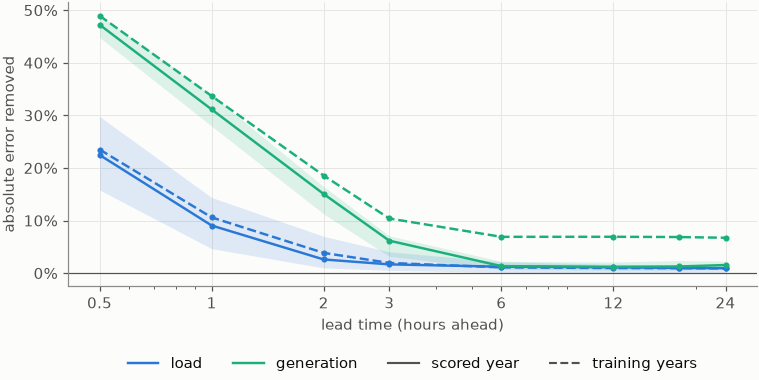

median skill over the households (1 = perfect, 0 = the 14-day median):
lead            0.5 h    1 h    2 h    3 h    6 h   12 h   18 h   24 h
channel period                                                        
load    test    0.225  0.091  0.026  0.017  0.012  0.011  0.010  0.009
        train   0.235  0.106  0.038  0.019  0.011  0.010  0.009  0.009
pv      test    0.472  0.311  0.150  0.062  0.013  0.012  0.013  0.015
        train   0.490  0.337  0.185  0.104  0.069  0.069  0.069  0.067


In [3]:
# The re-issued AR forecast against the bare 14-day median, by lead time: the
# share of the median's absolute error it removes, median over the households.
# Solid is the scored year; dashed is the training years, where the AR's
# coefficients were fitted -- the gap is what a learner trained on these rows
# over-trusts them by.
SK = rx.ar_skill(IDS)
fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.5))
hours = np.array(sorted(SK.lead.unique())) * rb.DELTA_T
CH = {"load": (SERIES[0], "load"), "pv": (SERIES[2], "generation")}
for ch, (col, lab) in CH.items():
    for period, ls in (("test", "-"), ("train", "--")):
        g = SK[(SK.channel == ch) & (SK.period == period)]
        # PCT formats percent values, so the skill is drawn as 0-100.
        med = g.groupby("lead").skill.median() * 100.0
        q = g.groupby("lead").skill.quantile([0.25, 0.75]).unstack() * 100.0
        ax.plot(hours, med.to_numpy(), ls=ls, color=col, lw=1.6, marker="o", ms=3)
        if period == "test":
            ax.fill_between(hours, q[0.25].to_numpy(), q[0.75].to_numpy(),
                            color=col, alpha=0.14, lw=0)
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_xscale("log")
ax.set_xticks([0.5, 1, 2, 3, 6, 12, 24])
ax.set_xticklabels(["0.5", "1", "2", "3", "6", "12", "24"])
ax.yaxis.set_major_formatter(PCT)
ax.grid(color=pf.GRID, lw=0.6)
ax.set_axisbelow(True)
handles = [Line2D([], [], color=c, lw=1.6, label=l) for c, l in CH.values()]
handles += [Line2D([], [], color=INK_2, lw=1.4, ls="-", label="scored year"),
            Line2D([], [], color=INK_2, lw=1.4, ls="--", label="training years")]
pf.key_legend(ax, handles, where="below", below_in=0.55, ncol=4)
finish(ax, title="What re-issuing the AR forecast every interval removes of the "
                 "14-day median's error",
       xlabel="lead time (hours ahead)",
       ylabel="absolute error removed")
pf.show(fig, "rlf_ar_skill")

t = (SK.groupby(["channel", "period", "lead"]).skill.median().unstack("lead")
     .rename(columns=lambda k: f"{k * rb.DELTA_T:g} h"))
print("median skill over the households (1 = perfect, 0 = the 14-day median):")
print(t.round(3).to_string())

## 2. The choice, on the held-out weeks

No test-year number is read here. Per tariff and learner, each contract against the panel's
on the measure that tariff is chosen on — AU the held-out bill net of wear; SI the same with
the contract charge the agent's own peaks agree (`rl_reward`'s held-out measure, which
reproduces the contract study's 67.41 EUR for the panel clone of Ausgrid 138). Filled marks
the contract a learner was given.

**On the held-out weeks almost nothing happens.** Every gain is within about ±3 per year,
against savings of 50–270, and the intervals straddle zero. The lowest mean still has to be
picked, and it picks differently in every cell: the working-day calendar for the two AU
imitators, the full four-bin contract for AU RL and the SI clone, the price rank for SI RL,
meter history for SI IL+RL. Section 5 shows why these weeks are a poor guide to this
particular question.

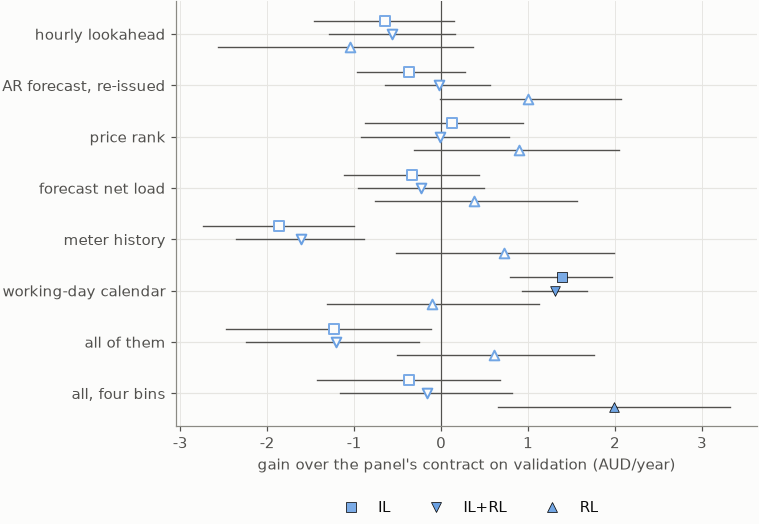

AU: validation gain over fc_h24, annualised, mean over the households (positive = cheaper)
learner                   IL  IL+RL    RL
input                                    
hourly lookahead       -0.65  -0.56 -1.05
AR forecast, re-issued -0.37  -0.02  1.00
price rank              0.12  -0.01  0.90
forecast net load      -0.33  -0.23  0.37
meter history          -1.86  -1.61  0.72
working-day calendar    1.38   1.31 -0.11
all of them            -1.24  -1.21  0.61
all, four bins         -0.37  -0.17  1.99
  selected: {'IL': 'working-day calendar', 'RL': 'all, four bins', 'IL+RL': 'working-day calendar'} 



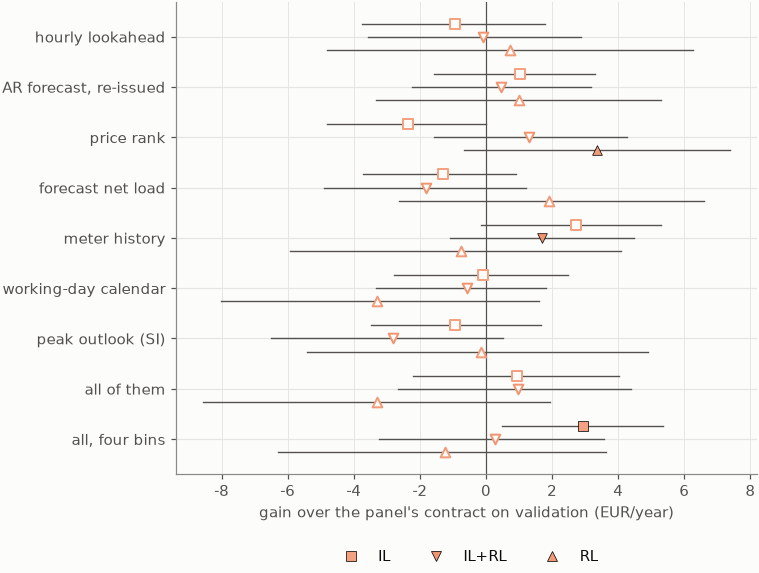

SI: validation gain over fc_h24, annualised, mean over the households (positive = cheaper)
learner                   IL  IL+RL    RL
input                                    
hourly lookahead       -0.95  -0.10  0.73
AR forecast, re-issued  1.03   0.47  0.99
price rank             -2.36   1.30  3.37
forecast net load      -1.30  -1.82  1.90
meter history           2.72   1.68 -0.75
working-day calendar   -0.08  -0.59 -3.30
peak outlook (SI)      -0.93  -2.83 -0.16
all of them             0.94   0.96 -3.31
all, four bins          2.93   0.29 -1.23
  selected: {'IL': 'all, four bins', 'RL': 'price rank', 'IL+RL': 'meter history'} 



In [4]:
# VALIDATION ONLY -- no test-year number is read in this cell. Each contract
# against the panel's, per learner, on the measure its tariff is chosen on
# (AU: held-out bill net of wear; SI: the same with the contract charge),
# annualised. Filled = the contract that learner was given.
VTAB = {}
for tariff in TARIFFS:
    variants = [v for v in INPUTS + COMBOS
                if v in set(VAL[VAL.tariff == tariff].variant)]
    fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.2 + 0.062 * len(variants)))
    VTAB[tariff] = gain_rows(ax, VAL, tariff, variants, "val_select",
                             scale=365.0 / DAYS, selected=PICK.get(tariff, {}))
    pf.key_legend(ax, method_handles(tariff), where="below", below_in=0.55, ncol=3)
    finish(ax, title=f"{tariff}: what each input is worth on the held-out weeks",
           xlabel=f"gain over the panel's contract on validation "
                  f"({hs.money(tariff, 'year')})", ylabel="")
    pf.show(fig, f"rlf_validation_{tariff}")
    print(f"{tariff}: validation gain over fc_h24, annualised, mean over the "
          f"households (positive = cheaper)")
    print(VTAB[tariff].pivot(index="input", columns="learner", values="mean")
          .reindex([NAME[v] for v in variants]).round(2).to_string())
    print("  selected:", {METHOD_NAME[m]: NAME.get(v, v)
                          for m, v in PICK.get(tariff, {}).items()}, "\n")

## 3. The test year

Read once. First, per learner, the contract chosen on validation against the panel's, one
point per household. The table adds the contract named in advance: every input at once.

- **The validation-chosen contracts gain in two cells of six.** AU RL on the full four-bin
  contract: **+14.5 AUD/a**, 28 of 30 households, p_holm < 0.001. The SI clone on the same
  contract: **+6.0 EUR/a**, 25 of 30, p_holm 0.047. The other four picks (calendar, calendar,
  price rank, meter history) are +1.8, +3.4, +4.3 and −1.6, none significant.
- **Every input at once gains in all six**: AU +4.2 (IL), +8.0 (RL), +8.2 (IL+RL) AUD/a; SI
  +6.0, +7.7, +7.5 EUR/a; 20–23 of 30 households each, p_holm 0.001–0.027 over the six cells.
  The four-bin version of it is ahead in five cells of six (AU +5.6 / +14.5 / +10.2, SI
  +6.0 / +7.0 / +9.3).
- So the inputs help, and the held-out weeks were a poor instrument for saying which
  contract carries the help — section 5.

**Three seeds** (last cell). The contract named in advance and the follow-up that turned out
best (section 5) were re-trained under seeds 1 and 2 and compared with the panel's contract
under the *same* seed — which exists: the hyperparameter study confirmed the panel's
settings on seeds 0–2. A local learner moves by several AUD/a between seeds on its own, so
this is what separates a contract's gain from a draw's.

- **Every input at once is positive under all three seeds in all six cells.** Averaged over
  seeds: AU **+6.4** (IL, 22 of 30 households), **+5.1** (RL, 23), **+11.0** (IL+RL, 29)
  AUD/a; SI **+7.6** (22), **+4.6** (16), **+7.6** (23) EUR/a; p_holm 0.0001–0.026. The one
  thin cell is SI RL (+7.7 / +2.0 / +4.0 by seed, 16 of 30 households).
- **The follow-up contract** (every input, four bins, prices against the trailing week):
  AU **+6.5 / +18.7 / +13.9** AUD/a (IL / RL / IL+RL), SI **+13.4 / +12.5 / +17.0** EUR/a,
  positive under every seed, 30 of 30 households for AU RL, AU IL+RL and SI IL+RL, all
  p_holm ≤ 0.001.

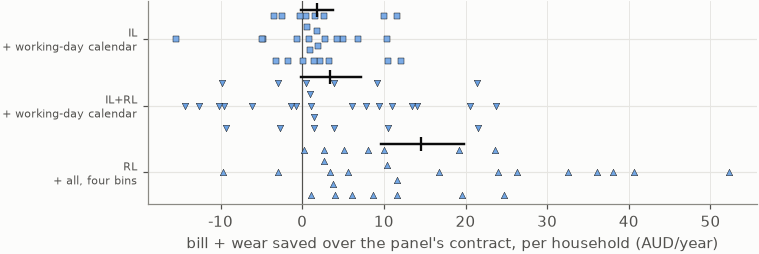

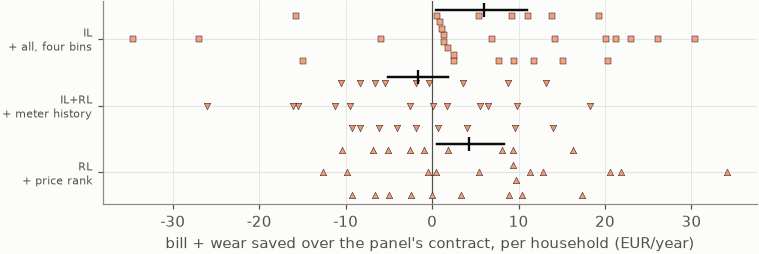

gain over fc_h24 on the test year (positive = cheaper); `selected` is the claim, Holm over its six cells;
`all` is every input at once, shown beside it and never chosen on these numbers
tariff method     role    variant  n   mean  median  better_on     p  p_holm     efc
    AU     bc selected        cal 30  1.812   1.526         21 0.058   0.231 198.001
    AU     bc      all        all 30  4.240   5.243         20 0.006     NaN 209.334
    AU    dqn selected all_coarse 30 14.530  10.202         28 0.000   0.000 188.500
    AU    dqn      all        all 30  7.989   9.391         23 0.001     NaN 185.263
    AU bc_dqn selected        cal 30  3.399   1.407         19 0.135   0.269 195.113
    AU bc_dqn      all        all 30  8.154   7.244         23 0.000     NaN 210.913
    SI     bc selected all_coarse 30  5.975   7.324         25 0.009   0.047 122.582
    SI     bc      all        all 30  5.963   8.197         23 0.020     NaN 124.621
    SI    dqn selected       rank 30  4.291   2.5

In [5]:
# THE TEST YEAR, read once. Per learner, the contract chosen on validation
# against the panel's: one point per household, the mean and its bootstrap CI.
HEAD = rx.headline(IDS, TARIFFS, PICK)
for tariff in TARIFFS:
    fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.36))
    for i, m in enumerate(METHODS):
        v = PICK.get(tariff, {}).get(m)
        if v in (None, BASE):
            ax.text(0, i, "  keeps the panel's contract", va="center",
                    fontsize=8, color=MUTED)
            continue
        d = gains(TEST, tariff, m, v, "test_net").to_numpy()
        col, mk = method_style(tariff, m)
        ax.scatter(d, i + fs.beeswarm(d), marker=mk, s=18, color=col,
                   edgecolor=INK, lw=0.3, zorder=3)
        lo, hi = fs.boot_ci(d, stat=np.mean)
        ax.plot([lo, hi], [i - 0.42, i - 0.42], color=INK, lw=1.6, zorder=4)
        ax.scatter([d.mean()], [i - 0.42], marker="|", s=90, color=INK, zorder=5)
    ax.set_yticks(range(len(METHODS)))
    ax.set_yticklabels([f"{METHOD_NAME[m]}\n+ {NAME.get(PICK.get(tariff, {}).get(m), '-')}"
                        for m in METHODS], fontsize=7.5)
    ax.invert_yaxis()
    ax.axvline(0, color=INK_2, lw=0.8)
    ax.xaxis.set_major_formatter(EUR)
    ax.grid(axis="x", color=pf.GRID, lw=0.6)
    ax.set_axisbelow(True)
    finish(ax, title=f"{tariff}: the selected inputs against the panel's, test year",
           xlabel=f"bill + wear saved over the panel's contract, per household "
                  f"({hs.money(tariff, 'year')})", ylabel="")
    pf.show(fig, f"rlf_headline_{tariff}")
print("gain over fc_h24 on the test year (positive = cheaper); `selected` is the "
      "claim, Holm over its six cells;\n`all` is every input at once, shown "
      "beside it and never chosen on these numbers")
print(HEAD[["tariff", "method", "role", "variant", "n", "mean", "median",
            "better_on", "p", "p_holm", "efc"]].round(3).to_string(index=False))

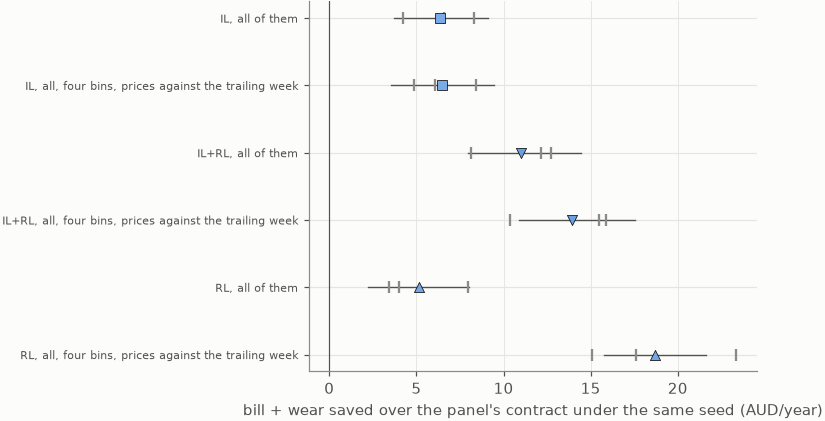

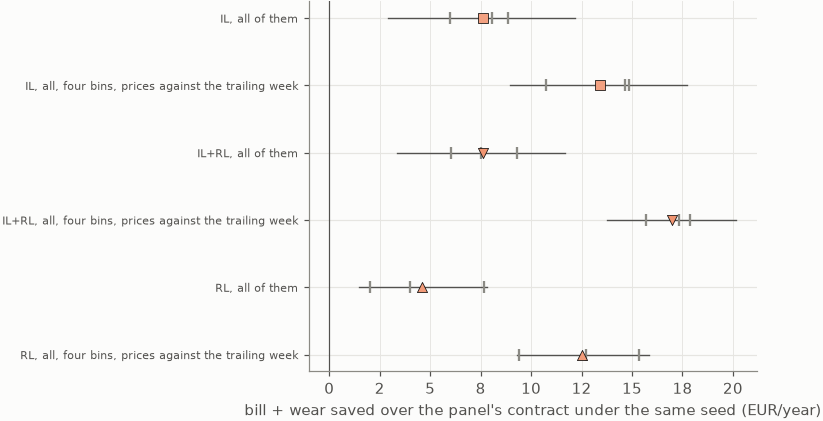

gain over fc_h24 under the same seed (s0, s1, s2), and the test on the households' seed-averaged gains; Holm over the six cells of a contract
tariff  n  seeds     s0     s1     s2   mean  median  better_on     p  p_holm learner                                         contract
    AU 30      3  4.240  6.592  8.281  6.371   5.407         22 0.000   0.000      IL                                      all of them
    AU 30      3  7.989  3.991  3.431  5.137   5.263         23 0.001   0.003      RL                                      all of them
    AU 30      3  8.154 12.749 12.152 11.018  10.648         29 0.000   0.000   IL+RL                                      all of them
    SI 30      3  5.963  8.833  8.080  7.625   8.867         22 0.005   0.010      IL                                      all of them
    SI 30      3  7.680  2.020  4.024  4.574   3.208         16 0.026   0.026      RL                                      all of them
    SI 30      3  7.540  9.289  6.056  7.628   9

In [6]:
# The two contracts that carry every input, re-trained under seeds 1 and 2 and
# compared with the panel's contract under the SAME seed. One row per learner
# and contract: the small ticks are the mean gain under each seed, the marker
# the mean of the households' seed-averaged gains with its bootstrap CI.
SEEDF = rx.seed_frame(IDS, TARIFFS)
STAB = rx.seed_table(IDS, TARIFFS)
for tariff in TARIFFS:
    keys = [(m, v) for m in METHODS for v in rx.SEED_VARIANTS]
    fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.2 + 0.062 * len(keys)))
    for i, (m, v) in enumerate(keys):
        sub = SEEDF[(SEEDF.tariff == tariff) & (SEEDF.method == m)]
        wide = sub.pivot_table(index=["ident", "seed"], columns="variant",
                               values="test_net")
        if v not in wide or BASE not in wide:
            continue
        gain = (wide[BASE] - wide[v]).dropna().unstack("seed").dropna()
        col, mk = method_style(tariff, m)
        mean = gain.mean(axis=1).to_numpy()
        lo, hi = fs.boot_ci(mean, stat=np.mean)
        ax.plot([lo, hi], [i, i], color=INK_2, lw=0.9, zorder=2)
        ax.scatter(gain.mean(axis=0).to_numpy(), [i] * gain.shape[1], marker="|",
                   s=70, color=MUTED, zorder=3)
        ax.scatter([mean.mean()], [i], marker=mk, s=44, color=col, edgecolor=INK,
                   lw=0.5, zorder=4)
    ax.set_yticks(range(len(keys)))
    ax.set_yticklabels([f"{METHOD_NAME[m]}, {NAME[v]}" for m, v in keys], fontsize=7.5)
    ax.invert_yaxis()
    ax.axvline(0, color=INK_2, lw=0.8)
    ax.xaxis.set_major_formatter(EUR)
    ax.grid(axis="x", color=pf.GRID, lw=0.6)
    ax.set_axisbelow(True)
    finish(ax, title=f"{tariff}: every input at once, three seeds, test year",
           xlabel=f"bill + wear saved over the panel's contract under the same seed "
                  f"({hs.money(tariff, 'year')})", ylabel="")
    pf.show(fig, f"rlf_seeds_{tariff}")
print("gain over fc_h24 under the same seed (s0, s1, s2), and the test on the "
      "households' seed-averaged gains; Holm over the six cells of a contract")
t = STAB.copy()
t["learner"] = t.method.map(METHOD_NAME)
t["contract"] = t.variant.map(NAME)
print(t.drop(columns=["method", "variant"]).round(3).to_string(index=False))

## 4. Each input alone, and given the others

The value-of-information table of `FIGURES_RL`, continued: every row is hollow because none
was chosen here. Then, for the clone, what the full contract loses when one input is taken
out — which is not what that input is worth alone when two of them carry the same fact.

- **One input alone is rarely worth anything, and the combination is.** Of the 39
  (learner, input) pairs only four survive Holm, three of them for AU RL (meter history +9.7,
  calendar +5.7) and IL+RL (price rank +7.5), and one in the wrong direction. The two
  contracts that carry everything are positive in all twelve cells.
- **The price rank is what the combination leans on.** Taken out of the full contract, the
  clone loses 4.8 AUD/a on AU (23 of 30, p_holm 0.02) and 6.7 EUR/a on SI; no other removal
  moves the bill by more than 1.4 on either tariff.
- **Meter history alone hurts the AU clone by 10.5 AUD/a** (26 of 30 worse, p < 0.001) and
  costs nothing inside the full contract. Eighteen more inputs to a 28 000-row fit, with
  nothing that says what a price is worth, is a way to overfit; the same columns are among
  the better single inputs for RL (+9.7), which is not fitted to labels.
- **The hourly lookahead and the re-issued AR forecast add nothing** — alone or given the
  rest — to any learner on either tariff. Four graded bins of a 14-day median are enough
  forecast for these controllers, which is the panel's own finding (only perfect foresight
  paid) from the other side: a *better* causal forecast, at any resolution, is not what they
  are short of. The full contract is better on four bins than on twenty-four for AU RL
  (−6.5 AUD/a with the hourly bins, p 0.01).
- **The peak outlook does nothing on SI** under the panel's reward, which does not pay for
  the line a peak moves (section 7 asks again under the reward that does).

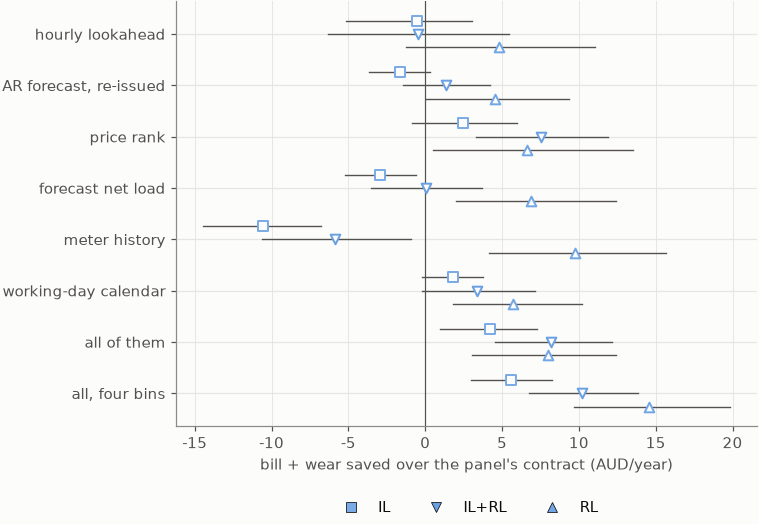

AU: each input alone, test year, paired over the households
learner                  input    mean  median  better_on  n     p  p_holm
     IL       hourly lookahead  -0.532   0.083         15 30 0.612   0.612
     IL AR forecast, re-issued  -1.665  -0.523         12 30 0.158   0.474
     IL             price rank   2.460   1.000         16 30 0.299   0.598
     IL      forecast net load  -2.938  -1.735          8 30 0.023   0.117
     IL          meter history -10.524  -8.832          4 30 0.000   0.000
     IL   working-day calendar   1.812   1.526         21 30 0.058   0.231
     IL            all of them   4.240   5.243         20 30 0.006   0.035
     IL         all, four bins   5.561   4.620         24 30 0.000   0.002
     RL       hourly lookahead   4.802   4.313         19 30 0.198   0.396
     RL AR forecast, re-issued   4.517   0.137         15 30 0.213   0.396
     RL             price rank   6.629   5.195         18 30 0.070   0.210
     RL      forecast net load   6.880  

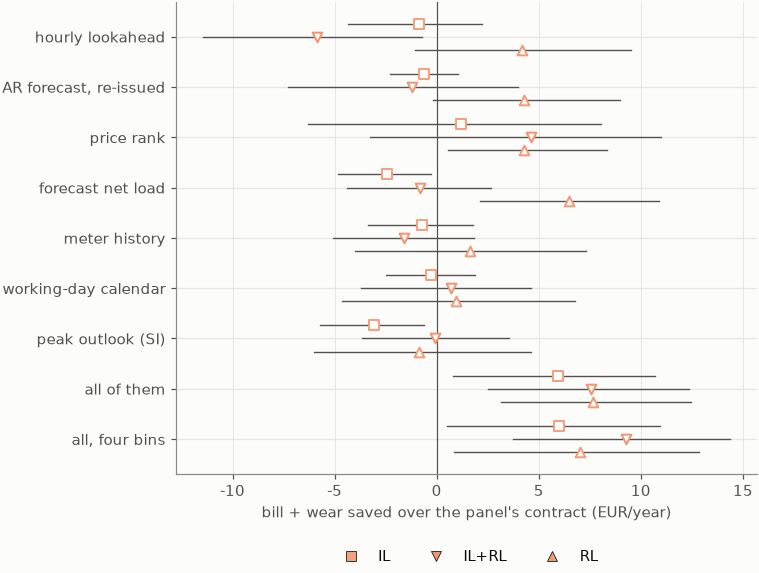

SI: each input alone, test year, paired over the households
learner                  input   mean  median  better_on  n     p  p_holm
     IL       hourly lookahead -0.867  -0.170         15 30 0.968   1.000
     IL AR forecast, re-issued -0.639  -0.809         12 30 0.328   1.000
     IL             price rank  1.190   3.775         20 30 0.360   1.000
     IL      forecast net load -2.450  -1.202         10 30 0.047   0.331
     IL          meter history -0.697   0.179         16 30 1.000   1.000
     IL   working-day calendar -0.294   0.391         15 30 0.887   1.000
     IL      peak outlook (SI) -3.072  -1.849         11 30 0.070   0.419
     IL            all of them  5.963   8.197         23 30 0.020   0.157
     IL         all, four bins  5.975   7.324         25 30 0.009   0.084
     RL       hourly lookahead  4.197   1.500         18 30 0.152   0.647
     RL AR forecast, re-issued  4.265   2.664         17 30 0.129   0.647
     RL             price rank  4.291   2.595       

In [7]:
# Every input on its own, on the test year: the value-of-information table of
# FIGURES_RL, continued. Hollow throughout -- none of these rows was chosen
# here, and reading the best of them off this figure would be choosing on the
# test year.
INFO = rx.information_value(IDS, TARIFFS)
for tariff in TARIFFS:
    variants = [v for v in INPUTS + COMBOS
                if v in set(TEST[TEST.tariff == tariff].variant)]
    fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.2 + 0.062 * len(variants)))
    gain_rows(ax, TEST, tariff, variants, "test_net", selected={})
    pf.key_legend(ax, method_handles(tariff), where="below", below_in=0.55, ncol=3)
    finish(ax, title=f"{tariff}: each input alone, test year",
           xlabel=f"bill + wear saved over the panel's contract "
                  f"({hs.money(tariff, 'year')})", ylabel="")
    pf.show(fig, f"rlf_inputs_test_{tariff}")
    t = INFO[(INFO.tariff == tariff) & (INFO.question == "alone")].copy()
    t["learner"] = t.method.map(METHOD_NAME)
    t["input"] = t.input.map(lambda v: NAME.get(v, v))
    print(f"{tariff}: each input alone, test year, paired over the households")
    print(t[["learner", "input", "mean", "median", "better_on", "n", "p",
             "p_holm"]].round(3).to_string(index=False), "\n")

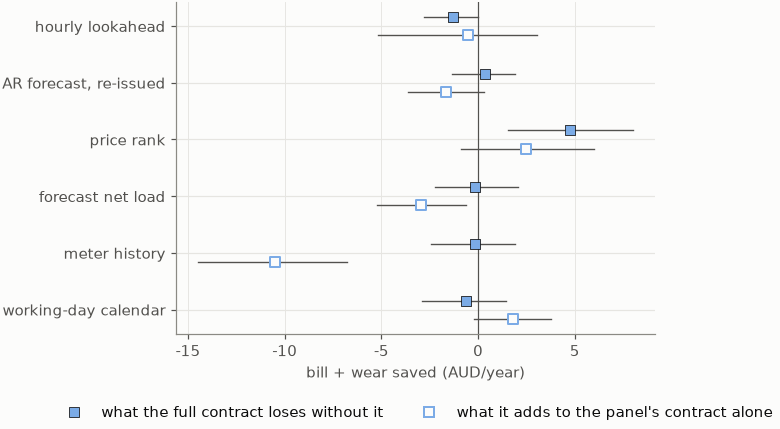

AU clone, mean over the households:
                        given the rest  alone
input                                        
hourly lookahead                 -1.32  -0.53
AR forecast, re-issued            0.34  -1.67
price rank                        4.76   2.46
forecast net load                -0.16  -2.94
meter history                    -0.15 -10.52
working-day calendar             -0.61   1.81 



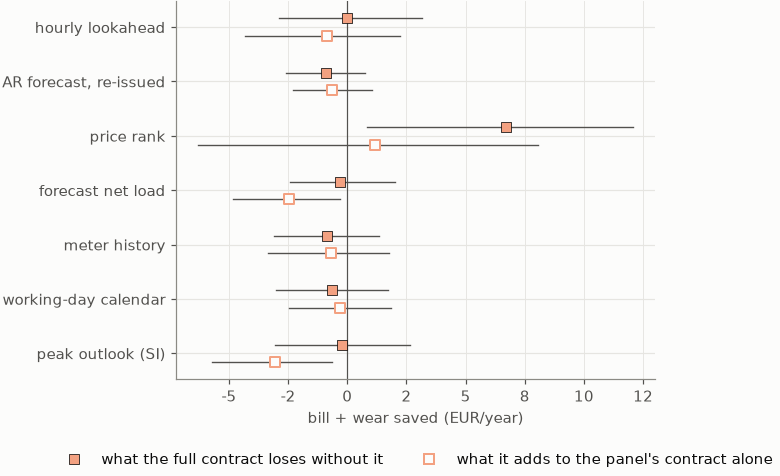

SI clone, mean over the households:
                        given the rest  alone
input                                        
hourly lookahead                 -0.01  -0.87
AR forecast, re-issued           -0.88  -0.64
price rank                        6.71   1.19
forecast net load                -0.30  -2.45
meter history                    -0.87  -0.70
working-day calendar             -0.63  -0.29
peak outlook (SI)                -0.23  -3.07 



In [8]:
# The clone only: what the full contract loses when one input is taken out
# (filled), beside what that input is worth alone (hollow). The two differ
# where inputs carry the same fact.
for tariff in TARIFFS:
    sub = TEST[(TEST.tariff == tariff) & (TEST.method == "bc")]
    have = set(sub.variant)
    inputs = [v for v in INPUTS if rx.LEAVE_OUT[v] in have and "all" in have]
    if not inputs:
        continue
    fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.2 + 0.062 * len(inputs)))
    col, mk = method_style(tariff, "bc")
    rows = []
    for i, v in enumerate(inputs):
        given = gains(TEST, tariff, "bc", "all", "test_net",
                      against=rx.LEAVE_OUT[v]).to_numpy()
        alone = gains(TEST, tariff, "bc", v, "test_net").to_numpy()
        for d, off, filled in ((given, -0.16, True), (alone, 0.16, False)):
            lo, hi = fs.boot_ci(d, stat=np.mean)
            ax.plot([lo, hi], [i + off, i + off], color=INK_2, lw=0.9, zorder=2)
            ax.scatter([d.mean()], [i + off], marker=mk, s=40, zorder=3,
                       facecolor=col if filled else SURFACE,
                       edgecolor=INK if filled else col,
                       lw=0.5 if filled else 1.3)
        rows.append({"input": NAME[v], "given the rest": given.mean(),
                     "alone": alone.mean()})
    ax.set_yticks(range(len(inputs)))
    ax.set_yticklabels([NAME[v] for v in inputs])
    ax.invert_yaxis()
    ax.axvline(0, color=INK_2, lw=0.8)
    ax.xaxis.set_major_formatter(EUR)
    ax.grid(axis="x", color=pf.GRID, lw=0.6)
    ax.set_axisbelow(True)
    pf.key_legend(ax, [
        Line2D([], [], marker=mk, ls="", color=col, markeredgecolor=INK,
               markeredgewidth=0.5, label="what the full contract loses without it"),
        Line2D([], [], marker=mk, ls="", markerfacecolor=SURFACE,
               markeredgecolor=col, markeredgewidth=1.3,
               label="what it adds to the panel's contract alone")],
        where="below", below_in=0.55, ncol=2)
    finish(ax, title=f"{tariff}: each input given the others, the clone, test year",
           xlabel=f"bill + wear saved ({hs.money(tariff, 'year')})", ylabel="")
    pf.show(fig, f"rlf_leave_out_{tariff}")
    print(tariff, "clone, mean over the households:")
    print(pd.DataFrame(rows).set_index("input").round(2).to_string(), "\n")

## 5. Why the held-out weeks could not see it — and what the inputs were really doing

**The held-out weeks understate everything.** The first figure sets each contract's gain on
the validation weeks against its gain on the test year. On validation nothing exceeds 3.4
per year; on the test year the same contracts reach 14.5. The two are barely related
(Spearman +0.47 on AU, +0.18 on SI).

**The reason is in the price list, not in the learners.** The validation weeks are every
fifth week of the *training* years: whatever those years have in common, validation has too.
What they have in common is a price level, and the scored year does not share it (second
cell). Its delivered import rate averages 19 % above the training years' on AU and 32 % above
on SI — on SI the scored year's 5th percentile sits at the training years' 95th — while the
mean daily spread, the thing a battery trades, is unchanged (−0 % and −3 %). A network shown
price *levels*, standardised on the training years, is extrapolating all year. One shown
where a price *ranks* is not. That is why the price rank is the one input the full contract
cannot lose, why it pays only where the level has moved, and why weeks cut from the training
years could not tell.

**The follow-up tests that reading directly** (third cell; trained after the test year had
been read, so it is evidence about the explanation and not part of the claim in section 3).
`FeatureSpec.price_reference = "trailing"` hands the network the panel's *own* price columns
— current rate, export credit, four bin means — minus the mean rate of the week before
(`rl_features.trailing_price`). No new information: the controller already holds that number.

- **On the panel's contract alone, that re-expression is worth more than every added input
  together.** SI: the clone +10.1 EUR/a (25 of 30), RL +15.5 (28 of 30), IL+RL +15.6 (29 of
  30) — against +6.0 / +7.0 / +9.3 for the full four-bin contract. AU: RL +17.0 AUD/a (28 of
  30) and IL+RL +8.6 (24 of 30); the AU clone +3.5, not significant.
- **Added to the full contract it is worth the same again where the level moved most**: SI
  +4.7 (clone), +8.3 (RL), +8.6 (IL+RL) over the full contract with levels, all p ≤ 0.001;
  AU RL +8.8 (29 of 30). The two AU imitators are unchanged (−0.7, +0.2): on AU the scored
  year is higher but inside the range the training years covered, and the level carries
  information there — EA025's network steps are absolute prices that say which period it is.
- **Together**: the full contract with prices against the trailing week takes SI from
  54.5 / 47.0 / 47.5 EUR/a (IL / RL / IL+RL) to **65.2 / 62.4 / 65.4**, and AU RL from 235.5
  to **258.8 AUD/a** (all 30 households better).

**And it can be checked on data the test year never touches** (fourth cell). The trained
models, unchanged, are rolled out on the held-out weeks of the training years twice: as they
are, and with the market price raised by the difference between the scored year's mean and
the training years'. Everything else is the panel's validation rollout.

- **Raising the level costs the level-reading contracts two to five times what it costs the
  trailing-week ones.** On AU the panel's contract loses 14.8 / 26.3 / 19.3 AUD/a of its
  held-out saving (IL / RL / IL+RL; every household worse), the same contract on trailing-week
  prices 7.5 / 5.3 / 7.2. On SI: 7.3 / 12.0 / 12.3 EUR/a against 2.5 / 0.5 / 1.8. (Nobody
  loses nothing: at a higher level round-trip losses cost more, whatever the controller reads.)
- **Adding the price rank does not protect a contract that still reads levels** (AU RL −22.0,
  SI IL+RL −14.0): the rank is there to be used, and the level columns beside it still move.
- **On these shifted weeks the choice would have come out right.** The full contract on
  trailing-week prices beats the panel's by 7 / 22 / 12 AUD/a on AU and 4 / 9 / 10 EUR/a on
  SI — the sign, and on AU nearly the size, of what the test year paid (4.9 / 23.4 / 10.4 and
  10.7 / 15.4 / 17.9). A validation split that keeps the price level of its training data
  cannot rank inputs by how they survive a change of level; one shifted to a level the
  controller has not seen can, without reading the test year.

Last cell of this section, for the clone: how much closer each contract brings it to its
teacher's choices, against what that is worth. The two rise together across contracts, but
the pooled clone (next section) shows that agreement is not the thing being bought.

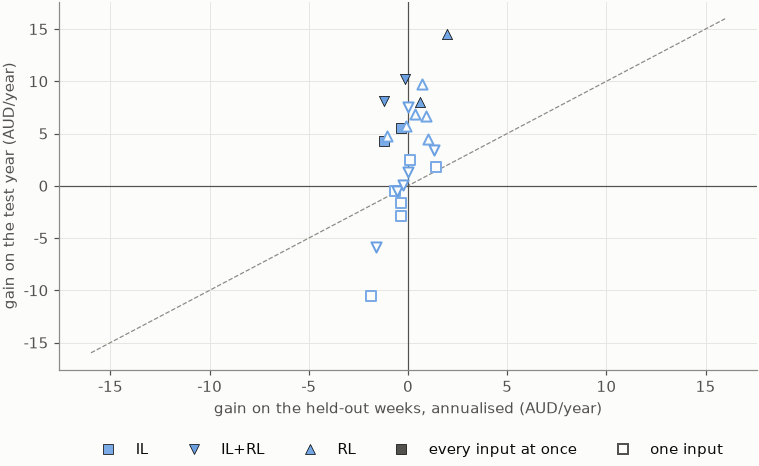

AU: 24 (contract, learner) pairs, Spearman rho between the validation gain and the test gain +0.47
                       validation             test            
learner                        IL IL+RL   RL    IL IL+RL    RL
input                                                         
hourly lookahead             -0.7  -0.6 -1.1  -0.5  -0.5   4.8
AR forecast, re-issued       -0.4  -0.0  1.0  -1.7   1.4   4.5
price rank                    0.1  -0.0  0.9   2.5   7.5   6.6
forecast net load            -0.3  -0.2  0.4  -2.9   0.1   6.9
meter history                -1.9  -1.6  0.7 -10.5  -5.9   9.7
working-day calendar          1.4   1.3 -0.1   1.8   3.4   5.7
all of them                  -1.2  -1.2  0.6   4.2   8.2   8.0
all, four bins               -0.4  -0.2  2.0   5.6  10.2  14.5 



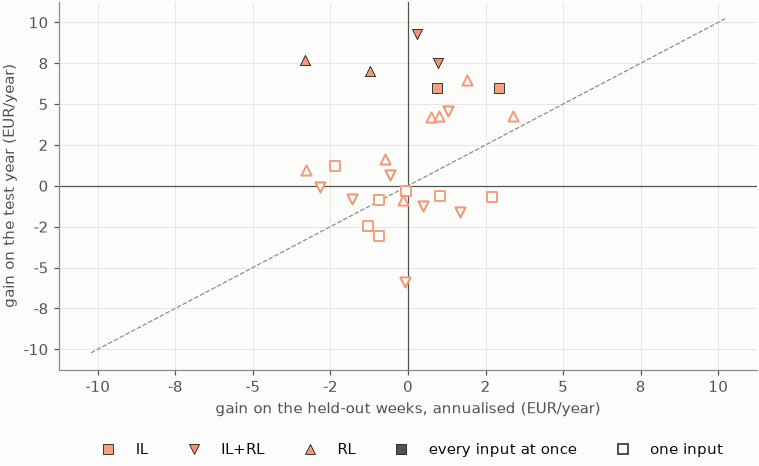

SI: 27 (contract, learner) pairs, Spearman rho between the validation gain and the test gain +0.18
                       validation            test           
learner                        IL IL+RL   RL   IL IL+RL   RL
input                                                       
hourly lookahead             -0.9  -0.1  0.7 -0.9  -5.9  4.2
AR forecast, re-issued        1.0   0.5  1.0 -0.6  -1.2  4.3
price rank                   -2.4   1.3  3.4  1.2   4.6  4.3
forecast net load            -1.3  -1.8  1.9 -2.4  -0.8  6.5
meter history                 2.7   1.7 -0.7 -0.7  -1.6  1.7
working-day calendar         -0.1  -0.6 -3.3 -0.3   0.7  1.0
peak outlook (SI)            -0.9  -2.8 -0.2 -3.1  -0.1 -0.9
all of them                   0.9   1.0 -3.3  6.0   7.5  7.7
all, four bins                2.9   0.3 -1.2  6.0   9.3  7.0 



In [9]:
# What the held-out weeks promised against what the test year paid: one point
# per contract and learner, both as gains over the panel's contract per year.
# On the diagonal the validation weeks would have been a faithful guide.
for tariff in TARIFFS:
    fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.62))
    rows = []
    for m in METHODS:
        col, mk = method_style(tariff, m)
        for v in INPUTS + COMBOS:
            x = gains(VAL, tariff, m, v, "val_select") * 365.0 / DAYS
            y = gains(TEST, tariff, m, v, "test_net")
            if x.empty or y.empty:
                continue
            wide_all = v in COMBOS
            ax.scatter([x.mean()], [y.mean()], marker=mk, s=44, zorder=3,
                       facecolor=col if wide_all else SURFACE,
                       edgecolor=INK if wide_all else col,
                       lw=0.5 if wide_all else 1.3)
            rows.append({"learner": METHOD_NAME[m], "input": NAME[v],
                         "validation": x.mean(), "test": y.mean()})
    r = pd.DataFrame(rows)
    lim = float(np.nanmax(np.abs(r[["validation", "test"]].to_numpy()))) * 1.1
    ax.plot([-lim, lim], [-lim, lim], color=MUTED, lw=0.8, ls="--", zorder=1)
    ax.axhline(0, color=INK_2, lw=0.8)
    ax.axvline(0, color=INK_2, lw=0.8)
    ax.xaxis.set_major_formatter(EUR)
    ax.yaxis.set_major_formatter(EUR)
    ax.grid(color=pf.GRID, lw=0.6)
    ax.set_axisbelow(True)
    handles = method_handles(tariff) + [
        Line2D([], [], marker="s", ls="", color=INK_2, markeredgecolor=INK,
               markeredgewidth=0.5, label="every input at once"),
        Line2D([], [], marker="s", ls="", markerfacecolor=SURFACE,
               markeredgecolor=INK_2, markeredgewidth=1.3, label="one input")]
    pf.key_legend(ax, handles, where="below", below_in=0.55, ncol=5)
    finish(ax, title=f"{tariff}: the held-out weeks understate what the inputs pay",
           xlabel=f"gain on the held-out weeks, annualised ({hs.money(tariff, 'year')})",
           ylabel=f"gain on the test year ({hs.money(tariff, 'year')})")
    pf.show(fig, f"rlf_val_vs_test_{tariff}")
    rho = r[["validation", "test"]].corr(method="spearman").iloc[0, 1]
    print(f"{tariff}: {len(r)} (contract, learner) pairs, Spearman rho between the "
          f"validation gain and the test gain {rho:+.2f}")
    print(r.pivot(index="input", columns="learner", values=["validation", "test"])
          .reindex([NAME[v] for v in INPUTS + COMBOS if NAME[v] in set(r.input)])
          .round(1).to_string(), "\n")

In [10]:
# The explanation the follow-up contracts test. The delivered import rate of
# one household's bundles (the price list is the same for all of them): its
# level in the two training years and in the scored year, and its mean daily
# spread -- the thing a battery trades.
rows = []
for tariff in TARIFFS:
    prep = rb.prepare_household(IDS[0], tariff)
    tr, te = prep["train"]["sig"].import_rate, prep["sim"]["sig"].import_rate
    spd = rb.H
    for name, a in (("training year 1", tr[:365 * spd]),
                    ("training year 2", tr[365 * spd:730 * spd]),
                    ("scored year", te[:365 * spd])):
        days = a[:len(a) // spd * spd].reshape(-1, spd)
        rows.append({"tariff": tariff, "period": name, "mean": a.mean(),
                     "5th pct": np.quantile(a, 0.05), "median": np.median(a),
                     "95th pct": np.quantile(a, 0.95),
                     "mean daily spread": (days.max(axis=1) - days.min(axis=1)).mean()})
SHIFT = pd.DataFrame(rows).set_index(["tariff", "period"])
print("delivered import rate per kWh, in the tariff's own currency")
print(SHIFT.round(4).to_string())
for tariff in TARIFFS:
    s = SHIFT.loc[tariff]
    print(f"{tariff}: the scored year's mean is "
          f"{s.loc['scored year', 'mean'] / s.iloc[:2]['mean'].mean() - 1:+.0%} "
          f"against the training years'; its daily spread "
          f"{s.loc['scored year', 'mean daily spread'] / s.iloc[:2]['mean daily spread'].mean() - 1:+.0%}")

delivered import rate per kWh, in the tariff's own currency
                          mean  5th pct  median  95th pct  mean daily spread
tariff period                                                               
AU     training year 1  0.1601   0.0861  0.1354    0.3211             0.2056
       training year 2  0.1610   0.0877  0.1367    0.3255             0.1904
       scored year      0.1904   0.1156  0.1656    0.3530             0.1978
SI     training year 1  0.0615   0.0504  0.0591    0.0716             0.0319
       training year 2  0.0621   0.0516  0.0615    0.0744             0.0219
       scored year      0.0815   0.0713  0.0799    0.0954             0.0261
AU: the scored year's mean is +19% against the training years'; its daily spread -0%
SI: the scored year's mean is +32% against the training years'; its daily spread -3%


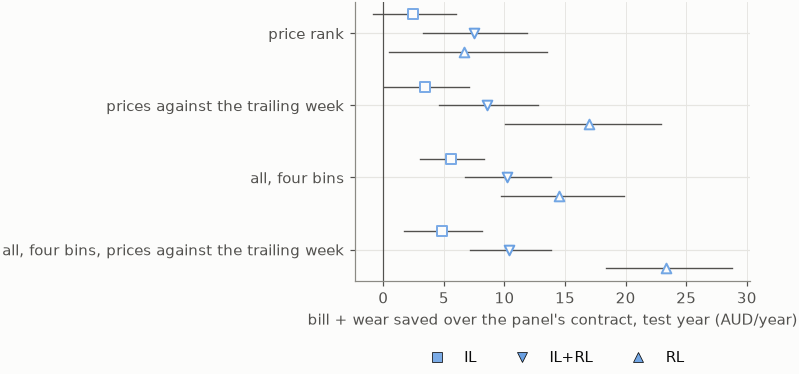

AU: gain over fc_h24 on the test year (positive = cheaper)
                                           input learner   mean  ci_lo  ci_hi  better_on  n     p
                                      price rank      IL  2.460 -0.863  5.990         16 30 0.299
                                      price rank   IL+RL  7.509  3.312 11.885         23 30 0.002
                                      price rank      RL  6.629  0.490 13.498         18 30 0.070
                prices against the trailing week      IL  3.472  0.017  7.110         16 30 0.135
                prices against the trailing week   IL+RL  8.587  4.635 12.804         24 30 0.000
                prices against the trailing week      RL 17.003 10.045 22.890         28 30 0.000
                                  all, four bins      IL  5.561  2.991  8.282         24 30 0.000
                                  all, four bins   IL+RL 10.193  6.739 13.837         24 30 0.000
                                  all, four bins      RL 14

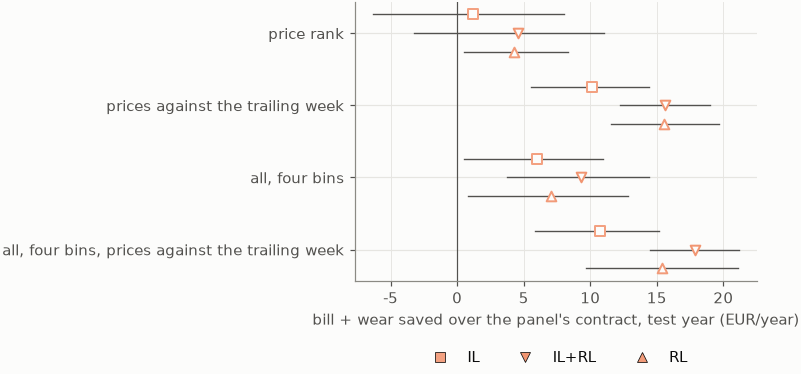

SI: gain over fc_h24 on the test year (positive = cheaper)
                                           input learner   mean  ci_lo  ci_hi  better_on  n     p
                                      price rank      IL  1.190 -6.308  8.054         20 30 0.360
                                      price rank   IL+RL  4.600 -3.254 10.999         20 30 0.023
                                      price rank      RL  4.291  0.534  8.323         17 30 0.080
                prices against the trailing week      IL 10.146  5.514 14.449         25 30 0.000
                prices against the trailing week   IL+RL 15.622 12.210 19.018         29 30 0.000
                prices against the trailing week      RL 15.506 11.569 19.705         28 30 0.000
                                  all, four bins      IL  5.975  0.493 10.940         25 30 0.009
                                  all, four bins   IL+RL  9.291  3.738 14.388         24 30 0.001
                                  all, four bins      RL  7

In [11]:
# FOLLOW-UP, trained after the test year had been read -- a test of the
# explanation, not part of the claim. The panel's contract with its prices
# re-expressed against the trailing week (no new information), beside the
# price rank alone; and the full contract with and without its price levels.
FVARS = ["rank", "rel", "all_coarse", "all_coarse_rel"]
FROWS = []
for tariff in TARIFFS:
    have = [v for v in FVARS if v in set(TEST[TEST.tariff == tariff].variant)]
    fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.2 + 0.075 * len(have)))
    tab = gain_rows(ax, TEST, tariff, have, "test_net", selected={})
    pf.key_legend(ax, method_handles(tariff), where="below", below_in=0.55, ncol=3)
    finish(ax, title=f"{tariff}: the same prices, measured against the last week",
           xlabel=f"bill + wear saved over the panel's contract, test year "
                  f"({hs.money(tariff, 'year')})", ylabel="")
    pf.show(fig, f"rlf_followup_{tariff}")
    print(f"{tariff}: gain over fc_h24 on the test year (positive = cheaper)")
    print(tab.round(3).to_string(index=False))
    for m in METHODS:
        r = rx.paired(TEST[(TEST.tariff == tariff) & (TEST.method == m)],
                      "all_coarse_rel", "all_coarse")
        if r:
            print(f"  {METHOD_NAME[m]}: the full contract WITHOUT price levels against "
                  f"with them: {r['mean']:+.2f} ({r['better_on']}/{r['n']} better, "
                  f"p {r['p']:.3f})")
    print()

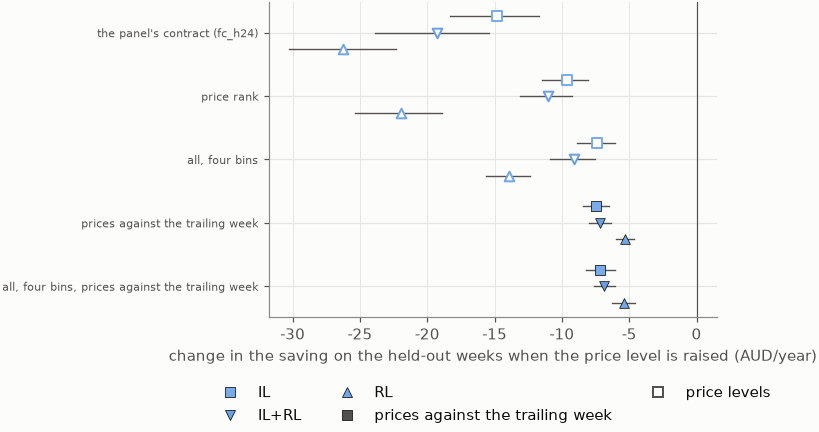

AU: market price raised by 0.0161 per kWh; saving against the idle pack on the held-out weeks, annualised
                                        contract learner  saving as is  saving shifted  change  ci_lo  ci_hi  worse_on  n
                   the panel's contract (fc_h24)      IL        276.99          262.15  -14.83 -18.34 -11.71        30 30
                   the panel's contract (fc_h24)   IL+RL        278.09          258.82  -19.26 -23.90 -15.43        30 30
                   the panel's contract (fc_h24)      RL        267.49          241.22  -26.27 -30.25 -22.34        30 30
                                      price rank      IL        277.11          267.51   -9.60 -11.50  -8.08        30 30
                                      price rank   IL+RL        278.08          267.06  -11.02 -13.12  -9.27        30 30
                                      price rank      RL        268.39          246.43  -21.96 -25.38 -18.88        30 30
                                  all, f

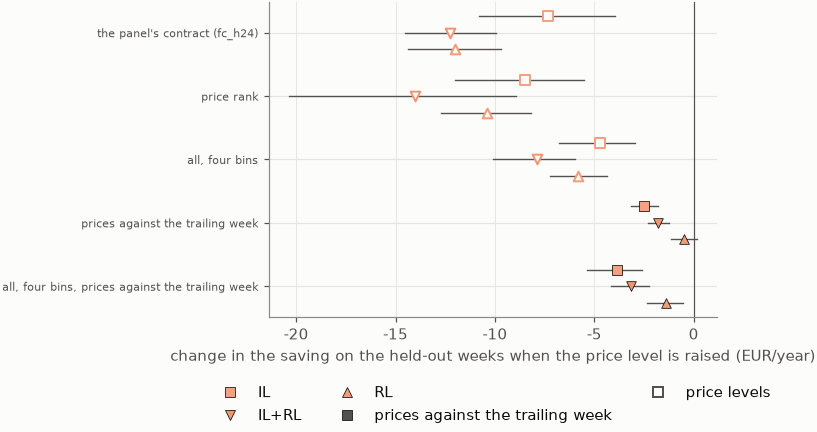

SI: market price raised by 0.0161 per kWh; saving against the idle pack on the held-out weeks, annualised
                                        contract learner  saving as is  saving shifted  change  ci_lo  ci_hi  worse_on  n
                   the panel's contract (fc_h24)      IL         48.71           41.37   -7.34 -10.78  -3.95        24 30
                   the panel's contract (fc_h24)   IL+RL         50.36           38.09  -12.27 -14.52  -9.94        29 30
                   the panel's contract (fc_h24)      RL         49.11           37.12  -11.99 -14.38  -9.69        30 30
                                      price rank      IL         47.81           39.31   -8.51 -11.99  -5.54        28 30
                                      price rank   IL+RL         49.42           35.40  -14.02 -20.35  -8.92        30 30
                                      price rank      RL         49.20           38.81  -10.40 -12.74  -8.17        30 30
                                  all, f

In [12]:
# HELD-OUT evidence for the explanation, which no test-year outcome touches:
# the trained models, unchanged, on the validation weeks of the training years
# -- as they are, and with the market price raised to the scored year's level.
# Plotted: what the shift does to each contract's saving against the idle
# pack on the same prices (annualised). Zero = the controller does not care
# what level the prices are at.
SHV = rx.shift_validation(IDS, TARIFFS)
SVARS = [v for v in rx.SHIFT_VARIANTS]
STABS = {}
for tariff in TARIFFS:
    sub = SHV[SHV.tariff == tariff]
    wide = sub.pivot_table(index=["variant", "method", "ident"], columns="shift",
                           values="saving")
    change = ((wide["shifted"] - wide["none"]) * 365.0 / DAYS).rename("change")
    fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.2 + 0.075 * len(SVARS)))
    offs = np.linspace(-0.26, 0.26, len(METHODS))
    rows = []
    for i, v in enumerate(SVARS):
        for off, m in zip(offs, METHODS):
            if (v, m) not in change.index.droplevel("ident"):
                continue
            d = change.loc[(v, m)].to_numpy()
            lo, hi = fs.boot_ci(d, stat=np.mean)
            col, mk = method_style(tariff, m)
            relative = v in rx.FOLLOW_UP
            ax.plot([lo, hi], [i + off, i + off], color=INK_2, lw=0.9, zorder=2)
            ax.scatter([d.mean()], [i + off], marker=mk, s=40, zorder=3,
                       facecolor=col if relative else SURFACE,
                       edgecolor=INK if relative else col,
                       lw=0.5 if relative else 1.3)
            base = wide.loc[(v, m)]
            rows.append({"contract": NAME.get(v, v), "learner": METHOD_NAME[m],
                         "saving as is": base["none"].mean() * 365.0 / DAYS,
                         "saving shifted": base["shifted"].mean() * 365.0 / DAYS,
                         "change": d.mean(), "ci_lo": lo, "ci_hi": hi,
                         "worse_on": int((d < -1e-9).sum()), "n": len(d)})
    STABS[tariff] = pd.DataFrame(rows)
    ax.set_yticks(range(len(SVARS)))
    ax.set_yticklabels([NAME.get(v, v) for v in SVARS], fontsize=7.5)
    ax.invert_yaxis()
    ax.axvline(0, color=INK_2, lw=0.8)
    ax.xaxis.set_major_formatter(EUR)
    ax.grid(axis="x", color=pf.GRID, lw=0.6)
    ax.set_axisbelow(True)
    handles = method_handles(tariff) + [
        Line2D([], [], marker="s", ls="", color=INK_2, markeredgecolor=INK,
               markeredgewidth=0.5, label="prices against the trailing week"),
        Line2D([], [], marker="s", ls="", markerfacecolor=SURFACE,
               markeredgecolor=INK_2, markeredgewidth=1.3, label="price levels")]
    pf.key_legend(ax, handles, where="below", below_in=0.55, ncol=3)
    finish(ax, title=f"{tariff}: the held-out weeks at the scored year's price level",
           xlabel=f"change in the saving on the held-out weeks when the price level "
                  f"is raised ({hs.money(tariff, 'year')})", ylabel="")
    pf.show(fig, f"rlf_shift_{tariff}")
    print(f"{tariff}: market price raised by {sub.delta_smp.mean():.4f} per kWh; "
          f"saving against the idle pack on the held-out weeks, annualised")
    print(STABS[tariff].round(2).to_string(index=False), "\n")

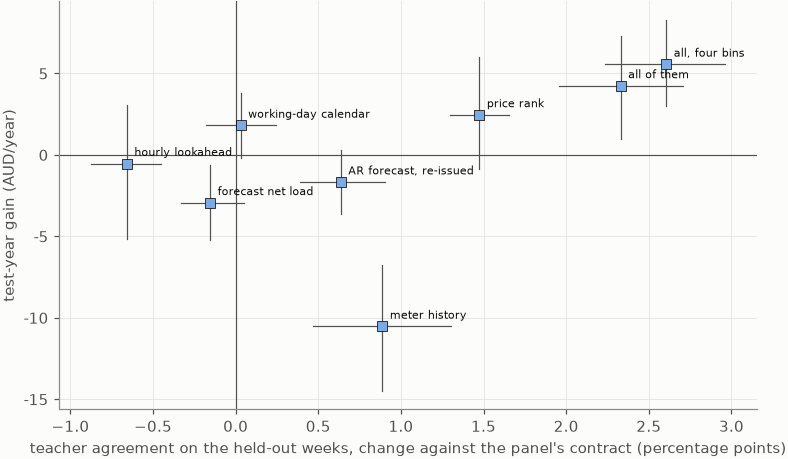

AU clone; the panel's contract agrees with its teacher on 0.876 of held-out intervals
                        agreement (pp)  test gain
contract                                         
hourly lookahead                 -0.66      -0.53
AR forecast, re-issued            0.64      -1.67
price rank                        1.47       2.46
forecast net load                -0.16      -2.94
meter history                     0.89     -10.52
working-day calendar              0.03       1.81
all of them                       2.33       4.24
all, four bins                    2.60       5.56 



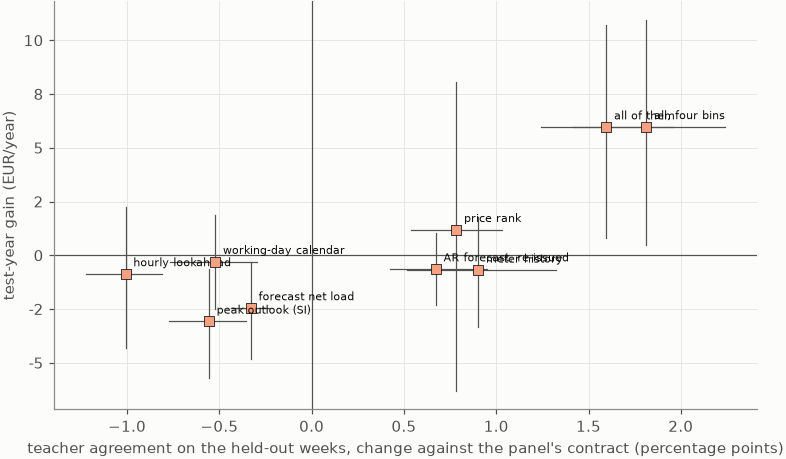

SI clone; the panel's contract agrees with its teacher on 0.843 of held-out intervals
                        agreement (pp)  test gain
contract                                         
hourly lookahead                 -1.01      -0.87
AR forecast, re-issued            0.67      -0.64
price rank                        0.78       1.19
forecast net load                -0.33      -2.45
meter history                     0.90      -0.70
working-day calendar             -0.52      -0.29
peak outlook (SI)                -0.56      -3.07
all of them                       1.60       5.96
all, four bins                    1.81       5.98 



In [13]:
# The clone again: how much closer each contract brings it to its teacher's
# choices on the held-out weeks (x), against what that is worth on the test
# year (y). One point per contract, mean over the households with bootstrap
# CIs both ways. If copying better meant paying less, the points would climb.
for tariff in TARIFFS:
    sub = TEST[(TEST.tariff == tariff) & (TEST.method == "bc")]
    agree = sub.pivot(index="ident", columns="variant", values="bc_agreement")
    variants = [v for v in INPUTS + COMBOS if v in agree]
    fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.62))
    col, mk = method_style(tariff, "bc")
    rows = []
    for v in variants:
        da = ((agree[v] - agree[BASE]) * 100.0).dropna().to_numpy()
        dg = gains(TEST, tariff, "bc", v, "test_net").to_numpy()
        alo, ahi = fs.boot_ci(da, stat=np.mean)
        glo, ghi = fs.boot_ci(dg, stat=np.mean)
        ax.plot([alo, ahi], [dg.mean()] * 2, color=INK_2, lw=0.8, zorder=2)
        ax.plot([da.mean()] * 2, [glo, ghi], color=INK_2, lw=0.8, zorder=2)
        ax.scatter([da.mean()], [dg.mean()], marker=mk, s=44, color=col,
                   edgecolor=INK, lw=0.5, zorder=3)
        ax.annotate(NAME[v], (da.mean(), dg.mean()), xytext=(5, 5),
                    textcoords="offset points", fontsize=7.5, color=INK)
        rows.append({"contract": NAME[v], "agreement (pp)": da.mean(),
                     "test gain": dg.mean()})
    ax.axhline(0, color=INK_2, lw=0.8)
    ax.axvline(0, color=INK_2, lw=0.8)
    ax.yaxis.set_major_formatter(EUR)
    ax.grid(color=pf.GRID, lw=0.6)
    ax.set_axisbelow(True)
    finish(ax, title=f"{tariff}: copying the teacher better is not paying less",
           xlabel="teacher agreement on the held-out weeks, change against the "
                  "panel's contract (percentage points)",
           ylabel=f"test-year gain ({hs.money(tariff, 'year')})")
    pf.show(fig, f"rlf_agreement_{tariff}")
    print(tariff, f"clone; the panel's contract agrees with its teacher on "
          f"{agree[BASE].mean():.3f} of held-out intervals")
    print(pd.DataFrame(rows).set_index("contract").round(2).to_string(), "\n")

## 6. The pooled clone: more inputs, same bill

One network over all 299 clustered households (`run_rl_global`'s `global` scheme, the study's
best learned controller), retrained through this driver on the panel's contract as the
control, and under two wider ones — every input group on four bins, and the same with the
hourly lookahead — each at the panel's width (64) and at 256. No AR here: only the 30 study
units have a fitted one. Three seeds each.

- **The wider inputs make the pooled clone copy its teacher better and pay no less.**
  Agreement on the held-out weeks rises from 0.881 to 0.905 (AU) and from 0.865 to 0.896
  (SI) — more than any single-household contract gained. On the test year the wider clones
  are between +0.5 and −2.6 AUD/a of the control on AU under every seed, and between +0.5
  and −15 EUR/a on SI; the validation-selected ones (AU all groups at width 256, SI + hourly at
  256) come out at −1.5 / −2.6 / −0.5 and +0.5 / −3.0 / −4.1 by seed. Nothing here is a gain.
- **Width alone hurts.** The panel's contract at width 256 is worse than at 64 in five of six
  (tariff, seed) cells, by up to −7.5 EUR/a on SI.
- **Wide inputs and pooling buy the same thing.** A single household's clone gains
  +5.6 AUD/a and +6.0 EUR/a from the full four-bin contract and lands at 266.9 and 60.4 —
  where the pooled clone on the panel's contract already is (268.5–269.5 AU, 59.0–62.4 SI).
  The two do not add.

**The follow-up rows** (prices against the trailing week, section 5; test-year figure only,
never candidates) split by tariff, as they do for the single-household learners:

- **SI: +7.5 EUR/a over the pooled control**, seed-averaged (24 of 30 households, p 0.0005;
  +10.0 / +6.9 / +5.6 by seed), with every input group and trailing-week prices, at either
  width. That is **68.0–69.3 EUR/a** under all three seeds — the best learned SI controller
  this study has produced, ahead of the pooled control (59.0–62.4) and of RL paid for the
  contract (59.7), 3 EUR/a short of the best rule (72.2). The same groups on price *levels*
  were the worst pooled SI clone (−7.7 to −15.2). The panel's contract with trailing-week
  prices and no groups: +1.6 to +2.0, not significant — on SI the pooled clone needs both.
- **AU: nothing.** Every group with trailing-week prices is −0.1 to −2.5 of the control under
  each seed, and trailing-week prices alone cost the pooled clone 3.4–4.5 AUD/a (25–27 of 30
  worse). Three hundred households of training rows had already taught it what the level
  shift costs a single household's clone; taking the level away removes what on EA025 says
  which tariff period it is.

In [14]:
# The pooled clone: one network over every clustered household, under the
# panel's contract (the control, retrained through this path) and two wider
# ones, each at two widths. Chosen on the study units' validation weeks.
PVAL = rx.pool_frame(IDS, TARIFFS)
PTEST = rx.pool_frame(IDS, TARIFFS, test=True)
with open(rx.POOL_SELECTION, encoding="utf-8") as fh:
    PPICK = json.load(fh)["picked"]
POOL_NAME = {rx.BASELINE: "the panel's contract", "groups": "all input groups",
             "all_no_ar": "all input groups + hourly lookahead",
             "rel": "follow-up: prices against the trailing week",
             "groups_rel": "follow-up: all groups, prices against the trailing week"}
POOL_ORDER = list(POOL_NAME)


def pool_models_of(frame, tariff):
    """The pooled clones of one tariff in reading order, the control left out."""
    models = frame[frame.tariff == tariff].model.unique()
    return [m for m in sorted(models, key=lambda m: (
        POOL_ORDER.index(m.rsplit("__h", 1)[0]), int(m.rsplit("__h", 1)[1])))
        if m != rx.POOL_CONTROL]


def pool_label(model):
    v, w = model.rsplit("__h", 1)
    return f"{POOL_NAME[v]}, width {w}"


def pool_gain(frame, tariff, model, value, seed=0, against=rx.POOL_CONTROL):
    sub = frame[(frame.tariff == tariff) & (frame.seed == seed)]
    wide = sub.pivot(index="ident", columns="model", values=value)
    if model not in wide or against not in wide:
        return pd.Series(dtype=float)
    return (wide[against] - wide[model]).dropna()


meta = pd.DataFrame([{**{k: m[k] for k in ("tariff", "variant", "hidden", "seed",
                                           "inputs", "epochs", "bc_val_agreement")},
                      "minutes": m["wall_s"] / 60.0, "households": len(m["members"])}
                     for m in (rx.pool_model(*x) for x in rx.pool_models(TARIFFS, rx.POOL_SEEDS))
                     if m is not None])
print("pooled clones on disk:")
print(meta.round(3).to_string(index=False))
print("selected on validation:", {t: pool_label(m) for t, m in PPICK.items()})

pooled clones on disk:
tariff    variant  hidden  seed  inputs  epochs  bc_val_agreement  minutes  households
    AU     fc_h24      64     0      23      14             0.881    5.452         299
    AU     fc_h24      64     1      23      11             0.882    3.830         299
    AU     fc_h24      64     2      23      18             0.882    6.096         299
    AU     fc_h24     256     0      23      14             0.881    8.659         299
    AU     fc_h24     256     1      23       6             0.882    3.734         299
    AU     fc_h24     256     2      23      13             0.882    7.913         299
    AU     groups      64     0      63       8             0.905    3.459         299
    AU     groups      64     1      63      10             0.908    4.073         299
    AU     groups      64     2      63      12             0.908    4.102         299
    AU     groups     256     0      63       8             0.905    5.304         299
    AU     groups   

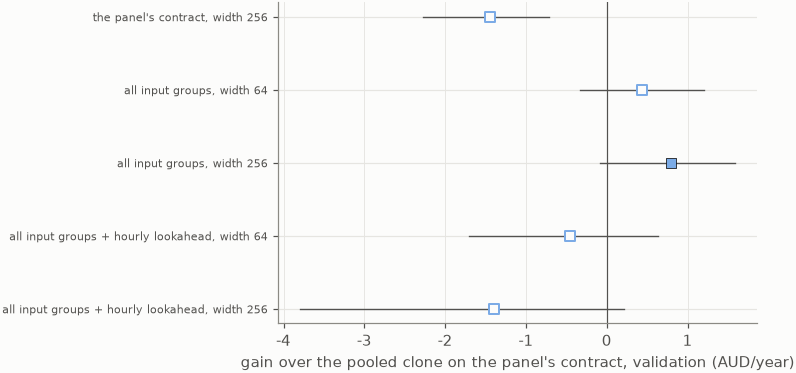

AU validation gain over the pooled control (width 64, the panel's contract), annualised
                                                mean  ci_lo  ci_hi  better_on   n
pooled clone                                                                     
the panel's contract, width 256                -1.44  -2.27  -0.71         11  30
all input groups, width 64                      0.44  -0.34   1.21         16  30
all input groups, width 256                     0.80  -0.09   1.59         22  30
all input groups + hourly lookahead, width 64  -0.45  -1.71   0.64         19  30
all input groups + hourly lookahead, width 256 -1.40  -3.79   0.22         11  30 



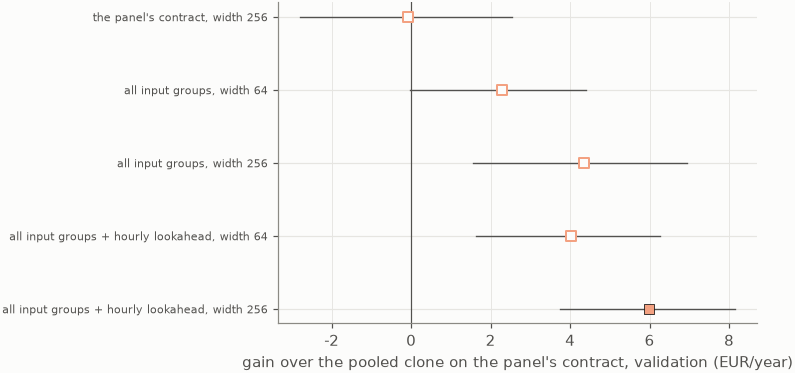

SI validation gain over the pooled control (width 64, the panel's contract), annualised
                                                mean  ci_lo  ci_hi  better_on   n
pooled clone                                                                     
the panel's contract, width 256                -0.08  -2.79   2.53         15  30
all input groups, width 64                      2.28  -0.02   4.39         23  30
all input groups, width 256                     4.34   1.55   6.95         23  30
all input groups + hourly lookahead, width 64   4.01   1.62   6.25         23  30
all input groups + hourly lookahead, width 256  5.99   3.75   8.15         25  30 



In [15]:
# VALIDATION ONLY. Each pooled clone against the pooled control on the study
# units' held-out weeks (seed 0), annualised. Filled = selected.
for tariff in TARIFFS:
    # The follow-ups were never candidates; they are not drawn on this axis.
    models = [m for m in pool_models_of(PVAL, tariff)
              if m.rsplit("__h", 1)[0] not in rx.POOL_FOLLOW_UP]
    fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.2 + 0.062 * len(models)))
    col, mk = method_style(tariff, "bc")
    rows = []
    for i, m in enumerate(models):
        d = pool_gain(PVAL, tariff, m, "val_select").to_numpy() * 365.0 / DAYS
        lo, hi = fs.boot_ci(d, stat=np.mean)
        chosen = PPICK.get(tariff) == m
        ax.plot([lo, hi], [i, i], color=INK_2, lw=0.9, zorder=2)
        ax.scatter([d.mean()], [i], marker=mk, s=44, zorder=3,
                   facecolor=col if chosen else SURFACE,
                   edgecolor=INK if chosen else col, lw=0.5 if chosen else 1.3)
        rows.append({"pooled clone": pool_label(m), "mean": d.mean(), "ci_lo": lo,
                     "ci_hi": hi, "better_on": int((d > 1e-9).sum()), "n": len(d)})
    ax.set_yticks(range(len(models)))
    ax.set_yticklabels([pool_label(m) for m in models], fontsize=7.5)
    ax.invert_yaxis()
    ax.axvline(0, color=INK_2, lw=0.8)
    ax.xaxis.set_major_formatter(EUR)
    ax.grid(axis="x", color=pf.GRID, lw=0.6)
    ax.set_axisbelow(True)
    finish(ax, title=f"{tariff}: the pooled clone under wider inputs, held-out weeks",
           xlabel=f"gain over the pooled clone on the panel's contract, validation "
                  f"({hs.money(tariff, 'year')})", ylabel="")
    pf.show(fig, f"rlf_pool_validation_{tariff}")
    print(tariff, "validation gain over the pooled control (width 64, the "
          "panel's contract), annualised")
    print(pd.DataFrame(rows).set_index("pooled clone").round(2).to_string(), "\n")

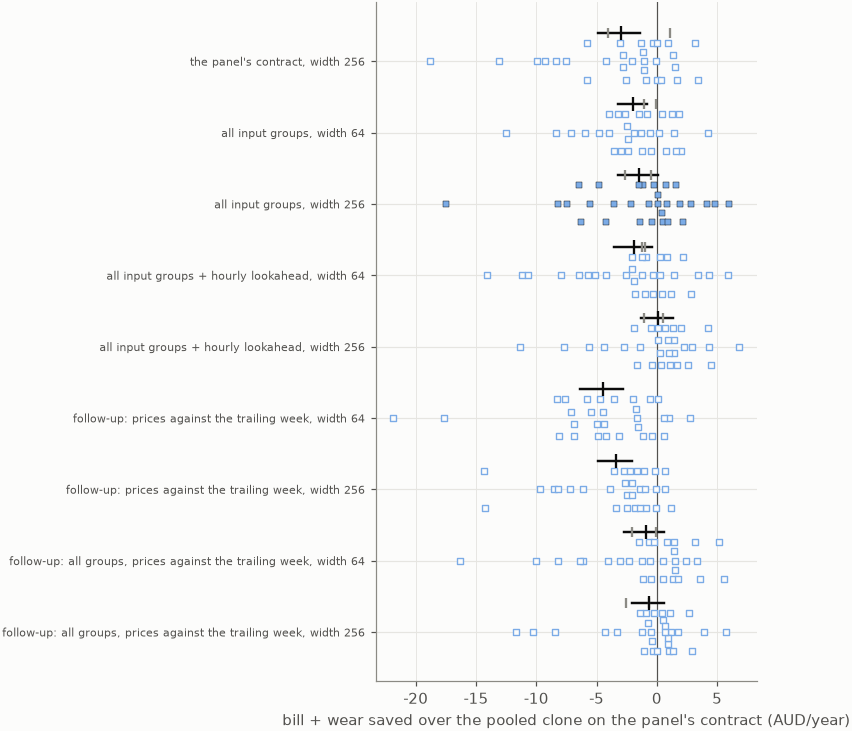

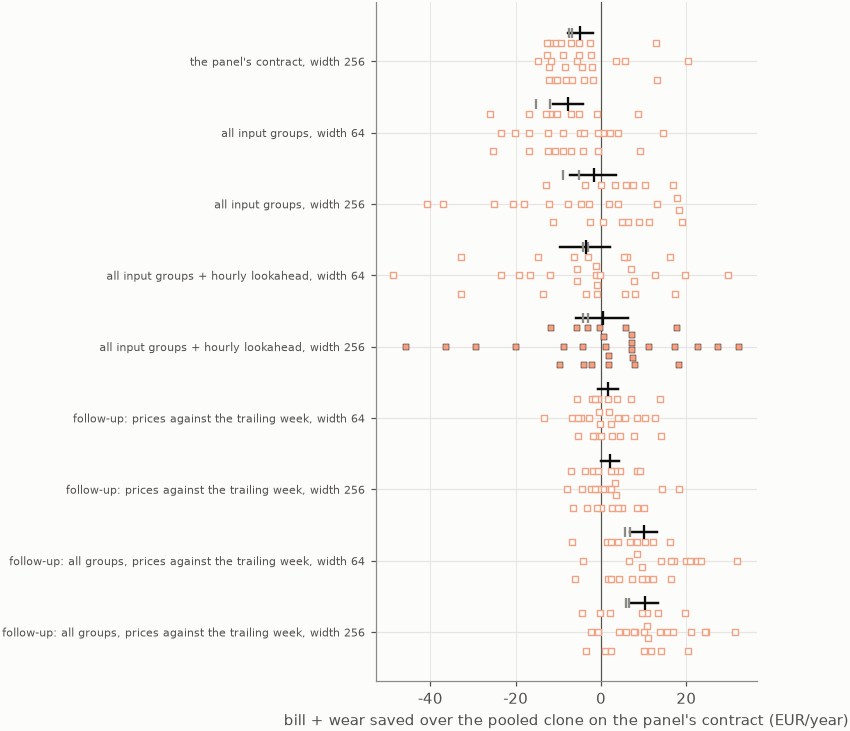

pooled clone, test year, gain over the pooled control (positive = cheaper); Holm within a tariff
tariff                                                       pooled clone  selected   mean   ci_lo  ci_hi  better_on  n     p            by seed  p_holm
    AU                                    the panel's contract, width 256     False -2.984  -4.850 -1.364          9 30 0.004   -3.0  +1.1  -4.0   0.022
    AU                                         all input groups, width 64     False -2.010  -3.255 -0.849          9 30 0.003   -2.0  -1.1  -0.1   0.021
    AU                                        all input groups, width 256      True -1.482  -3.189  0.083         14 30 0.229   -1.5  -2.6  -0.5   0.914
    AU                      all input groups + hourly lookahead, width 64     False -1.924  -3.593 -0.370         11 30 0.052   -1.9  -1.2  -0.9   0.261
    AU                     all input groups + hourly lookahead, width 256     False  0.075  -1.306  1.307         20 30 0.360   +0.1  -1.1

In [16]:
# THE TEST YEAR. Every pooled clone against the pooled control, one point per
# household (seed 0); the bar is the mean and its bootstrap CI. Small ticks
# under a row are the same mean under the other seeds, where they were run.
PROWS = []
for tariff in TARIFFS:
    models = pool_models_of(PTEST, tariff)
    fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.2 + 0.085 * len(models)))
    col, mk = method_style(tariff, "bc")
    ps = []
    for i, m in enumerate(models):
        d = pool_gain(PTEST, tariff, m, "test_net")
        chosen = PPICK.get(tariff) == m
        ax.scatter(d, i + fs.beeswarm(d.to_numpy(), height=0.26), marker=mk, s=16,
                   facecolor=col if chosen else SURFACE,
                   edgecolor=INK if chosen else col, lw=0.3 if chosen else 0.9,
                   zorder=3)
        lo, hi = fs.boot_ci(d.to_numpy(), stat=np.mean)
        ax.plot([lo, hi], [i - 0.4, i - 0.4], color=INK, lw=1.6, zorder=4)
        ax.scatter([d.mean()], [i - 0.4], marker="|", s=90, color=INK, zorder=5)
        seeds = {}
        for sd in rx.POOL_SEEDS:
            ds = pool_gain(PTEST, tariff, m, "test_net", seed=sd)
            if len(ds):
                seeds[sd] = ds.mean()
                if sd:
                    ax.scatter([ds.mean()], [i - 0.4], marker="|", s=40,
                               color=MUTED, zorder=4)
        sub = PTEST[(PTEST.tariff == tariff) & (PTEST.seed == 0)]
        wide = sub.pivot(index="ident", columns="model", values="test_net")
        r = hs.paired_comparison(wide, rx.POOL_CONTROL, m)
        ps.append(r["p_value"])
        PROWS.append({"tariff": tariff, "pooled clone": pool_label(m),
                      "selected": chosen, "mean": d.mean(), "ci_lo": lo,
                      "ci_hi": hi, "better_on": int((d > 1e-9).sum()),
                      "n": len(d), "p": r["p_value"],
                      "by seed": "  ".join(f"{v:+.1f}" for v in seeds.values())})
    for row, p_h in zip(PROWS[-len(models):], fs.holm(ps)):
        row["p_holm"] = p_h
    ax.set_yticks(range(len(models)))
    ax.set_yticklabels([pool_label(m) for m in models], fontsize=7.5)
    ax.invert_yaxis()
    ax.axvline(0, color=INK_2, lw=0.8)
    ax.xaxis.set_major_formatter(EUR)
    ax.grid(axis="x", color=pf.GRID, lw=0.6)
    ax.set_axisbelow(True)
    finish(ax, title=f"{tariff}: the pooled clone under wider inputs, test year",
           xlabel=f"bill + wear saved over the pooled clone on the panel's "
                  f"contract ({hs.money(tariff, 'year')})", ylabel="")
    pf.show(fig, f"rlf_pool_test_{tariff}")
PTAB = pd.DataFrame(PROWS)
print("pooled clone, test year, gain over the pooled control (positive = cheaper); "
      "Holm within a tariff")
print(PTAB.round(3).to_string(index=False))

## 7. SI, paid for the contract

The panel pays an SI learner for the settled bill against the no-battery contract.
`FIGURES_RL_CONTRACT` built the reward that also pays the standing charge the agent's own
peaks re-agree, under which reinforcement became the best learned SI controller (59.7 EUR/a).
That arm — its reward, its settings, its validation measure, `run_rl_contract.run_one` itself
— is trained here under three wider observations and compared with that study's own
`fc_h24` runs. The first figure is the held-out weeks (the choice), the second the test year.

- **The two imitators gain what they gained under the panel's reward**: the clone +6.6
  (all groups, selected; 22 of 30, p_holm 0.005) to +7.8 EUR/a, IL+RL +10.0 (selected; 23 of
  30, p_holm 0.004) to +10.3.
- **Reinforcement — the arm's best learner — gets worse with every wider observation**:
  −3.9 and −4.2 EUR/a with the input groups (not significant), −6.0 with the peak outlook
  alone (22 of 30 worse, p < 0.001). The held-out weeks saw it and kept the panel's contract.
  Paid for the contract, the DQN already reads the contract threshold in its state; the
  outlook columns give it more to fit and nothing it lacked.
- **The peak outlook alone helps nobody**, here either. What a peak costs is carried by the
  reward and by the contract features that arm already has, not by a forecast of the draw.

The last cell is the panel's SI runs by bill line. For the two imitators the wider contracts
do not pay through energy at all: the price rank costs the clone 9.8 EUR/a on the settled
bill and returns 11.0 on the **standing charge** — it trades with the grid at better-chosen
times and so presents lower peaks, which under a contract re-agreed from them is where the
money is. For RL the same inputs pay about half on each line.

**Follow-up** (the last two rows of the test-year figure; prices against the trailing week,
trained after the test year was read and never candidates): the imitators gain again — the
clone +11.1 on the panel's contract re-expressed and +13.6 with every input (67.3 EUR/a),
IL+RL +18.9 and +20.5 (67.3; 28 of 30 households). RL gains +4.3 on the re-expressed panel
contract (64.0 EUR/a, 21 of 30, p 0.013) and nothing once the other inputs are added (−0.2).
The learner that was already the best on this arm is the one with the least to gain from a
wider observation, twice over.

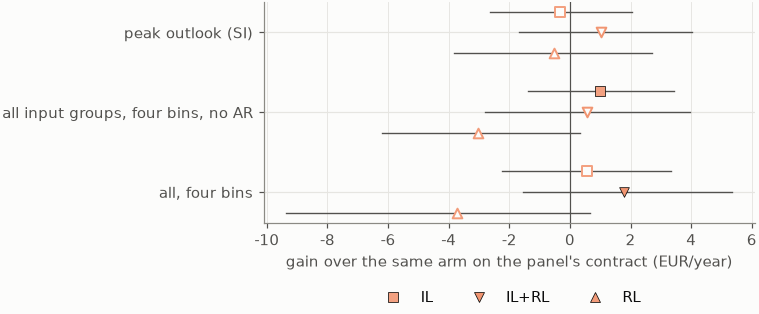

SI contract-paid arm, held-out weeks, with the contract charge: gain over fc_h24 (positive = cheaper)
                             input learner   mean  ci_lo  ci_hi  better_on  n     p
                 peak outlook (SI)      IL -0.314 -2.635  2.043         16 30 0.839
                 peak outlook (SI)   IL+RL  1.010 -1.691  4.027         17 30 0.641
                 peak outlook (SI)      RL -0.516 -3.833  2.711         14 30 0.887
all input groups, four bins, no AR      IL  0.990 -1.381  3.428         14 30 0.777
all input groups, four bins, no AR   IL+RL  0.575 -2.809  3.947         20 30 0.328
all input groups, four bins, no AR      RL -3.018 -6.200  0.346         10 30 0.043
                    all, four bins      IL  0.569 -2.232  3.342         14 30 0.700
                    all, four bins   IL+RL  1.787 -1.546  5.360         21 30 0.164
                    all, four bins      RL -3.722 -9.372  0.657         11 30 0.253 



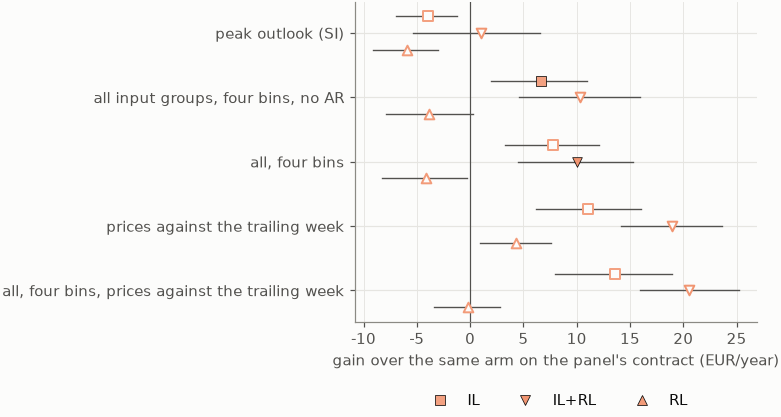

SI contract-paid arm, test year, total bill + wear: gain over fc_h24 (positive = cheaper)
                                           input learner   mean  ci_lo  ci_hi  better_on  n     p
                               peak outlook (SI)      IL -3.944 -6.926 -1.262          9 30 0.009
                               peak outlook (SI)   IL+RL  1.023 -5.328  6.567         16 30 0.452
                               peak outlook (SI)      RL -5.965 -9.096 -2.998          8 30 0.001
              all input groups, four bins, no AR      IL  6.609  1.997 10.973         22 30 0.005
              all input groups, four bins, no AR   IL+RL 10.299  4.606 15.946         21 30 0.002
              all input groups, four bins, no AR      RL -3.850 -7.889  0.308         12 30 0.092
                                  all, four bins      IL  7.768  3.293 12.116         22 30 0.001
                                  all, four bins   IL+RL 10.000  4.516 15.282         23 30 0.002
                            

In [17]:
# SI learners PAID FOR THE CONTRACT (the contract study's reward, settings and
# validation measure), under three wider observations, against that study's
# own fc_h24 runs. First the held-out weeks -- the choice -- then the test year.
CVAL = rx.contract_frame(IDS)
CTEST = rx.contract_frame(IDS, test=True)
with open(rx.CONTRACT_SELECTION, encoding="utf-8") as fh:
    CPICK = json.load(fh)["picked"]
CMAIN = [v for v in rx.contract_specs() if v not in rx.FOLLOW_UP]
CVARS = CMAIN + [v for v in rx.contract_specs() if v in rx.FOLLOW_UP]
for frame, value, scale, tag, what, rows_ in (
        (CVAL, "val", 365.0 / DAYS, "validation",
         "held-out weeks, with the contract charge", CMAIN),
        (CTEST.dropna(subset=["test_net"]), "test_net", 1.0, "test",
         "test year, total bill + wear", CVARS)):
    fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.2 + 0.07 * len(rows_)))
    tab = gain_rows(ax, frame, "SI", rows_, value, scale=scale, selected=CPICK)
    pf.key_legend(ax, method_handles("SI"), where="below", below_in=0.55, ncol=3)
    finish(ax, title=f"SI, paid for the contract: wider inputs, {what}",
           xlabel=f"gain over the same arm on the panel's contract "
                  f"({hs.money('SI', 'year')})", ylabel="")
    pf.show(fig, f"rlf_contract_{tag}")
    print(f"SI contract-paid arm, {what}: gain over fc_h24 (positive = cheaper)")
    print(tab.round(3).to_string(index=False), "\n")
print("selected on validation:", {METHOD_NAME[m]: NAME.get(v, v) for m, v in CPICK.items()})
nb_si = REFS[(REFS.tariff == "SI") & (REFS.controller == "no_battery")].set_index("ident").test_net
lvl = CTEST.dropna(subset=["test_net"]).assign(saving=lambda d: d.ident.map(nb_si) - d.test_net)
print("\nmean saving against no battery, test year (EUR/a), and cycles per year:")
print(lvl.pivot_table(index="variant", columns="method", values=["saving", "efc"])
      .reindex([BASE] + CVARS).round(1).to_string())

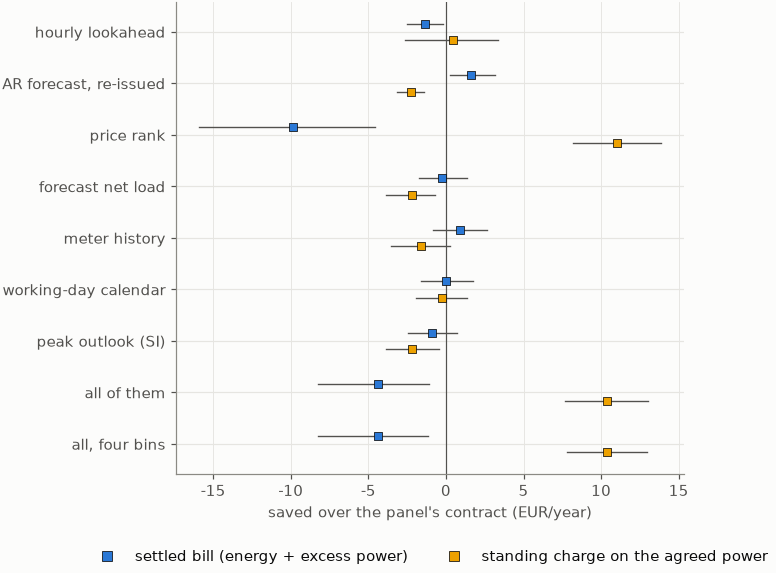

SI IL: mean gain over fc_h24 by bill line
                        settled bill  standing charge
input                                                
hourly lookahead               -1.34             0.48
AR forecast, re-issued          1.61            -2.25
price rank                     -9.84            11.03
forecast net load              -0.26            -2.19
meter history                   0.92            -1.62
working-day calendar           -0.01            -0.28
peak outlook (SI)              -0.91            -2.16
all of them                    -4.39            10.36
all, four bins                 -4.39            10.36 



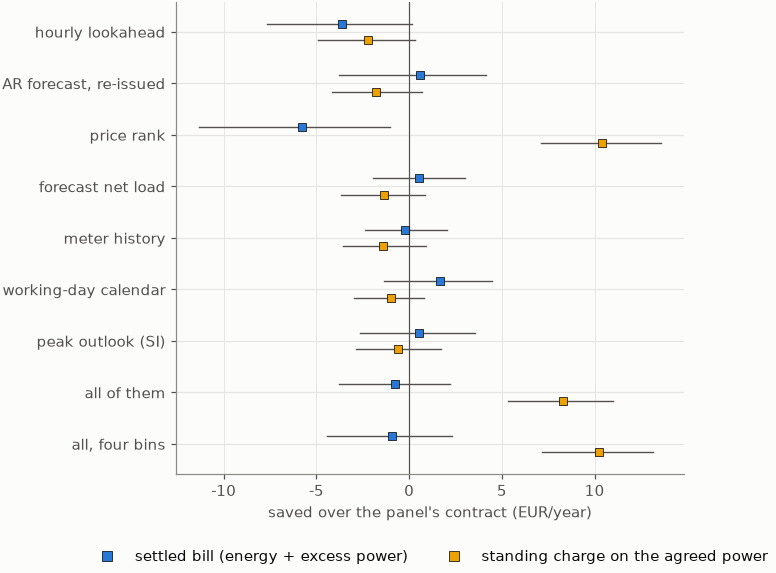

SI IL+RL: mean gain over fc_h24 by bill line
                        settled bill  standing charge
input                                                
hourly lookahead               -3.64            -2.22
AR forecast, re-issued          0.58            -1.81
price rank                     -5.80            10.40
forecast net load               0.55            -1.37
meter history                  -0.22            -1.39
working-day calendar            1.64            -0.96
peak outlook (SI)               0.52            -0.58
all of them                    -0.76             8.30
all, four bins                 -0.92            10.21 



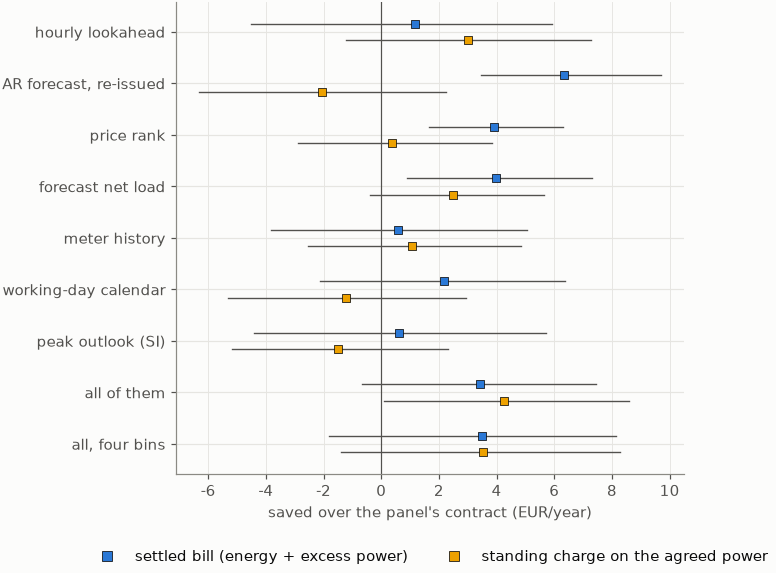

SI RL: mean gain over fc_h24 by bill line
                        settled bill  standing charge
input                                                
hourly lookahead                1.18             3.02
AR forecast, re-issued          6.33            -2.07
price rank                      3.91             0.38
forecast net load               3.99             2.50
meter history                   0.58             1.08
working-day calendar            2.19            -1.23
peak outlook (SI)               0.62            -1.49
all of them                     3.42             4.26
all, four bins                  3.49             3.52 



In [18]:
# SI only: which line of the bill an input moves. The gain over the panel's
# contract split into the settled bill (energy + excess power, closed out) and
# the standing charge on the agreed power the agent's own peaks set.
tariff = "SI"
variants = [v for v in INPUTS + COMBOS if v in set(TEST[TEST.tariff == tariff].variant)]
LINE = {"cost_eur_closed": (SERIES[0], "settled bill (energy + excess power)"),
        "fixed_eur": (SERIES[3], "standing charge on the agreed power")}
for m in METHODS:
    fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.2 + 0.062 * len(variants)))
    rows = []
    for i, v in enumerate(variants):
        rec = {"input": NAME[v]}
        for off, (col_name, (col, lab)) in zip((-0.16, 0.16), LINE.items()):
            d = gains(TEST, tariff, m, v, col_name).to_numpy()
            if not len(d):
                continue
            lo, hi = fs.boot_ci(d, stat=np.mean)
            ax.plot([lo, hi], [i + off, i + off], color=INK_2, lw=0.9, zorder=2)
            ax.scatter([d.mean()], [i + off], marker="s", s=34, color=col,
                       edgecolor=INK, lw=0.5, zorder=3)
            rec[lab.split(" (")[0].split(" on")[0]] = d.mean()
        rows.append(rec)
    ax.set_yticks(range(len(variants)))
    ax.set_yticklabels([NAME[v] for v in variants])
    ax.invert_yaxis()
    ax.axvline(0, color=INK_2, lw=0.8)
    ax.xaxis.set_major_formatter(EUR)
    ax.grid(axis="x", color=pf.GRID, lw=0.6)
    ax.set_axisbelow(True)
    pf.key_legend(ax, [Line2D([], [], marker="s", ls="", color=c,
                              markeredgecolor=INK, markeredgewidth=0.5, label=l)
                       for c, l in LINE.values()],
                  where="below", below_in=0.55, ncol=2)
    finish(ax, title=f"SI, {METHOD_NAME[m]}: which bill line each input moves",
           xlabel=f"saved over the panel's contract ({hs.money(tariff, 'year')})",
           ylabel="")
    pf.show(fig, f"rlf_si_lines_{m}")
    print(f"SI {METHOD_NAME[m]}: mean gain over fc_h24 by bill line")
    print(pd.DataFrame(rows).set_index("input").round(2).to_string(), "\n")

## 8. Where the learned controllers stand now

Every controller on one axis — the saving against no battery on the test year's total bill
plus wear, seed 0 — beside the study's own rules, its best deployable MPC and the whole-year
MILP. Hollow: the panel's inputs. Filled: every input at once, the contract named before the
test year was read. Starred labels are follow-up contracts, trained after it.

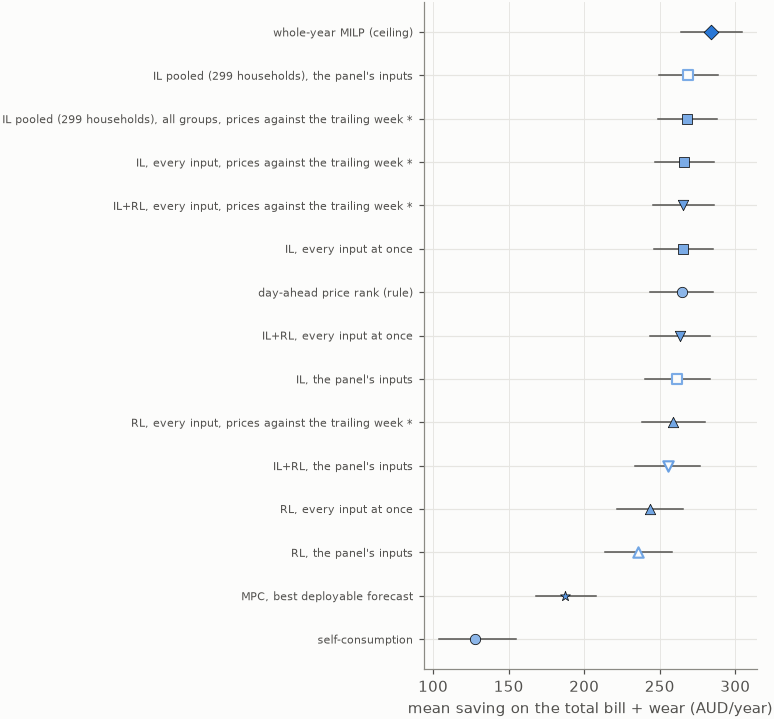

AU mean saving against no battery, bootstrap 95 % CI  (* = follow-up contract, trained after the test year was read)
                                                                             mean  ci_lo  ci_hi   n
controller                                                                                         
self-consumption                                                            127.7  103.8  154.6  30
MPC, best deployable forecast                                               187.3  168.0  208.0  30
RL, the panel's inputs                                                      235.5  213.5  258.1  30
RL, every input at once                                                     243.5  221.5  265.7  30
IL+RL, the panel's inputs                                                   255.3  233.8  276.8  30
RL, every input, prices against the trailing week *                         258.8  238.6  279.6  30
IL, the panel's inputs                                                      261.4  

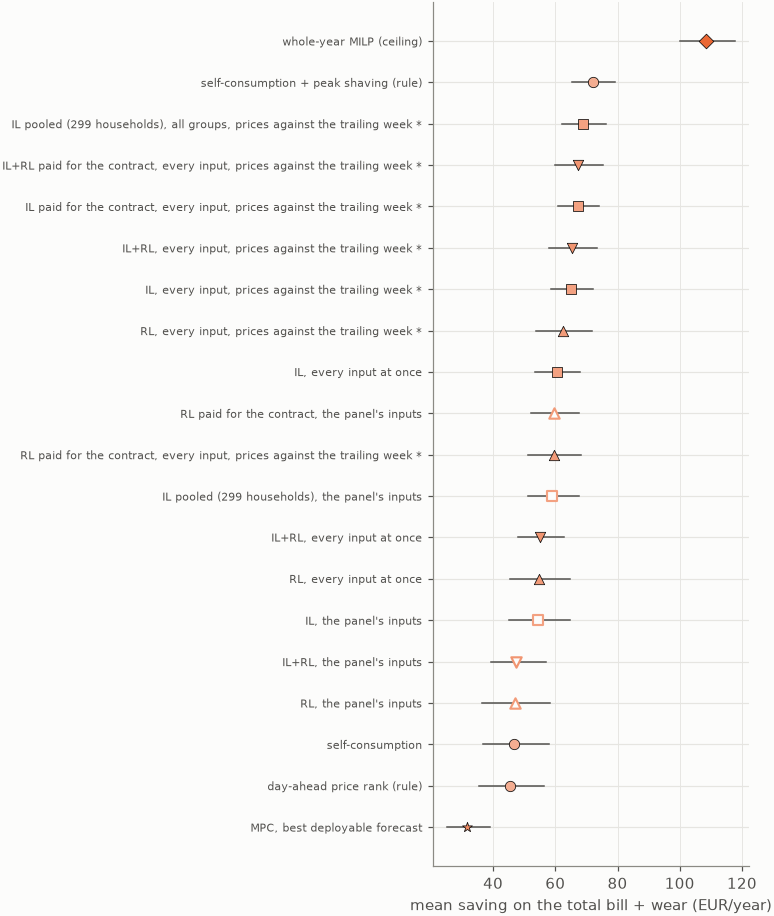

SI mean saving against no battery, bootstrap 95 % CI  (* = follow-up contract, trained after the test year was read)
                                                                               mean  ci_lo  ci_hi   n
controller                                                                                           
MPC, best deployable forecast                                                  31.6   25.3   38.9  30
day-ahead price rank (rule)                                                    45.3   35.5   56.4  30
self-consumption                                                               46.8   36.9   58.0  30
RL, the panel's inputs                                                         47.0   36.4   58.4  30
IL+RL, the panel's inputs                                                      47.5   39.4   56.9  30
IL, the panel's inputs                                                         54.5   45.1   64.7  30
RL, every input at once                                            

In [19]:
# Where the learned controllers stand now, beside the study's own controllers
# on the same households and the same axis: the saving against no battery on
# the test year's total bill plus wear (seed 0). Per learner: the panel's
# inputs (hollow), every input at once -- the contract named before the test
# year was read (filled) -- and the best follow-up contract (filled, starred
# label: trained after the test year was read). The pooled clones likewise.
REF_NAME = {"self_consumption": "self-consumption",
            "price_rank_daily": "day-ahead price rank (rule)",
            "self_consumption_peak_shaving": "self-consumption + peak shaving (rule)",
            "mpc_hbd_median14": "MPC, best deployable forecast",
            "milp_full": "whole-year MILP (ceiling)"}
REF_KEY = {"self_consumption": "self_consumption",
           "price_rank_daily": "price_rank_daily",
           "self_consumption_peak_shaving": "self_consumption_peak_shaving",
           "mpc_hbd_median14": "prophet", "milp_full": "milp_full"}
RANK = {}
for tariff in TARIFFS:
    nb = REFS[(REFS.tariff == tariff) & (REFS.controller == "no_battery")
              ].set_index("ident").test_net
    series = {}
    for c in REF_NAME:
        r = REFS[(REFS.tariff == tariff) & (REFS.controller == c)].set_index("ident")
        if len(r) and not (tariff == "AU" and c == "self_consumption_peak_shaving"):
            series[("ref", c, REF_NAME[c])] = (nb - r.test_net).dropna()
    for m in METHODS:
        for role, v, lab in (("panel", BASE, "the panel's inputs"),
                             ("wide", "all", "every input at once"),
                             ("follow", "all_coarse_rel",
                              "every input, prices against the trailing week *")):
            r = TEST[(TEST.tariff == tariff) & (TEST.method == m)
                     & (TEST.variant == v)].set_index("ident")
            if len(r):
                series[(role, m, f"{METHOD_NAME[m]}, {lab}")] = (nb - r.test_net).dropna()
    pooled = PTEST[(PTEST.tariff == tariff) & (PTEST.seed == 0)]
    for role, model, lab in (("panel", rx.POOL_CONTROL, "the panel's inputs"),
                             ("follow", "groups_rel__h64",
                              "all groups, prices against the trailing week *")):
        r = pooled[pooled.model == model].set_index("ident")
        if len(r):
            series[(role, "bc", f"IL pooled (299 households), {lab}")] = (
                nb - r.test_net).dropna()
    if tariff == "SI":
        # The contract-paid arm (section 7): its best learner on the panel's
        # inputs, and each learner on the follow-up contract.
        paid = CTEST.dropna(subset=["test_net"])
        for role, m, v, lab in [("panel", "dqn", BASE, "the panel's inputs")] + [
                ("follow", m, "all_coarse_rel",
                 "every input, prices against the trailing week *") for m in METHODS]:
            r = paid[(paid.method == m) & (paid.variant == v)].set_index("ident")
            if len(r):
                series[(role, m, f"{METHOD_NAME[m]} paid for the contract, {lab}")] = (
                    nb - r.test_net).dropna()
    order = sorted(series, key=lambda k: series[k].mean())
    fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.2 + 0.05 * len(order)))
    rows = []
    for i, key in enumerate(order):
        v = series[key].to_numpy()
        lo, hi = fs.boot_ci(v, stat=np.mean)
        kind, name, label = key
        ctrl = REF_KEY[name] if kind == "ref" else f"{name}_{BASE}"
        col, mk = fs.ctrl_color(tariff, ctrl), fs.ctrl_marker(ctrl)
        hollow = kind == "panel"
        ax.plot([lo, hi], [i, i], color=INK_2, lw=1.0, zorder=2)
        ax.scatter([v.mean()], [i], marker=mk, s=46, zorder=3,
                   facecolor=SURFACE if hollow else col,
                   edgecolor=col if hollow else INK, lw=1.4 if hollow else 0.5)
        rows.append({"controller": label, "mean": v.mean(), "ci_lo": lo,
                     "ci_hi": hi, "n": len(v)})
    RANK[tariff] = pd.DataFrame(rows).set_index("controller")
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels(RANK[tariff].index, fontsize=7)
    ax.xaxis.set_major_formatter(EUR)
    ax.grid(axis="x", color=pf.GRID, lw=0.6)
    ax.set_axisbelow(True)
    finish(ax, title=f"{tariff}: saving against no battery, test year",
           xlabel=f"mean saving on the total bill + wear "
                  f"({hs.money(tariff, 'year')})", ylabel="")
    pf.show(fig, f"rlf_ranking_{tariff}")
    print(tariff, "mean saving against no battery, bootstrap 95 % CI  "
          "(* = follow-up contract, trained after the test year was read)")
    print(RANK[tariff].round(1).to_string(), "\n")

## 9. What the numbers rest on

Every model above was trained under the panel's tuned settings and split; reinforcement runs
whose validation was still improving at 500 000 steps were re-trained at 1 000 000, as the
panel's were. The panel's own `fc_h24` results are read, never rewritten, and their digests
are unchanged by the new `FeatureSpec` fields (`test_rl_features.py`, 42 checks: causality of
every column under a poisoned meter, no cold start at the scored year, layout, digests).

In [20]:
# What the numbers above rest on.
runs = TEST[TEST.variant != BASE]
print(f"scored runs: {len(runs)}  (households {runs.ident.nunique()}, "
      f"contracts {runs.variant.nunique()})")
rl_runs = runs[runs.method != "bc"]
print(f"reinforcement runs settled: {int(rl_runs.converged.sum())}/{len(rl_runs)}")
late = VAL[(VAL.method != "bc") & (VAL.steps == rx.RETRAIN_STEPS)
           & (VAL.variant != BASE)]
print(f"  of which re-trained at {rx.RETRAIN_STEPS:,} steps: {len(late)}")
print("cycles per year, mean (the pack's life is cycle-limited above ~500):")
print(TEST[TEST.variant.isin([BASE] + INPUTS + COMBOS)]
      .pivot_table(index="variant", columns=["tariff", "method"], values="efc")
      .reindex([BASE] + INPUTS + COMBOS).round(0).to_string())

scored runs: 2220  (households 30, contracts 17)
reinforcement runs settled: 1260/1260
  of which re-trained at 1,000,000 steps: 89
cycles per year, mean (the pack's life is cycle-limited above ~500):
tariff         AU                   SI              
method         bc bc_dqn    dqn     bc bc_dqn    dqn
variant                                             
fc_h24      194.0  192.0  166.0   93.0  101.0  132.0
fine        199.0  194.0  178.0  103.0  115.0  145.0
ar          190.0  189.0  173.0   90.0   95.0  133.0
rank        204.0  205.0  187.0  116.0  127.0  140.0
net         191.0  192.0  171.0   87.0   92.0  130.0
hist        182.0  181.0  179.0   92.0   93.0  138.0
cal         198.0  195.0  172.0   94.0   95.0  130.0
peak          NaN    NaN    NaN   85.0   96.0  139.0
all         209.0  211.0  185.0  125.0  137.0  151.0
all_coarse  207.0  207.0  188.0  123.0  126.0  134.0


## 10. What this does and does not show

- **The claim that was set up before the test year was read**: with every input at once the
  three learners improve on both tariffs (section 3), and the held-out weeks would have told
  you so in two cells of six. That part stands on its own.
- **The larger result is a follow-up.** Measuring prices against the trailing week was tried
  *because* the test year showed the price rank carrying the gain, and there is one test
  year. What supports it without that year: the price-level shift is a fact of the input
  data (section 5, second cell), the representation carries no new information, and the
  held-out weeks at the shifted level reproduce the ordering (section 5, fourth cell). What
  would settle it is a second scored year, which this data does not have.
- **Hyperparameters are the panel's**, searched for 23–27 inputs (`rl_hpo`), and were not
  searched again for 63–135. The wide contracts are, if anything, under-served; the one
  width check that was run (the pooled clone at 256) made things worse.
- **Nothing about a forecast improved anything.** A finer lookahead and a better short-lead
  forecast are the two inputs that added nothing to any learner. What these controllers were
  short of was a stationary reading of a signal they already had.
- **Pooled models**: imitation only, and without the AR (fitted for the 30 study units only).
- **What was promoted (2026-10-12).** The follow-up contract of section 5 is now the
  panel's `wide_h24` (`run_rl_benchmark.variant_specs`; the same spec, so the models trained
  here are the panel's) and what `hs.LEARNED_CONTROLLERS` joins onto the study frame:
  `FIGURES_RL` and `CODE.ipynb` show the learned controllers under it. `fc_h24` and its
  ablations are unchanged and still answer the value-of-information questions. The pooled
  and contract studies were not re-run under it beyond what sections 6 and 7 show.
- **A validation split for robustness.** Every input or representation choice in this study
  that is about surviving a change — of year, of price level, of contract — will look like
  nothing on weeks cut from the training years. The shifted rollout of section 5
  (`run_rl_features.shift_validation`) costs seconds per model and would have made this
  choice correctly; it is the split to use for the next one.

## 11. Hyperparameters for the wide contract

Every model above was trained with the panel's settings, which were searched under
`fc_h24`'s 23–27 inputs. The wide contract has 63–75, so the search was run again in its own
right (`rl_hpo` with `ERK_HPO_VARIANT=wide_h24`, results under `results_local/rl_hpo_wide/`):
the same spaces, the same 16 (IL) and 8 (RL, IL+RL) tuning households that are not study
units, TPE with pruning, the top three and the incumbent re-trained under two more seeds, and
the winner scored once against the panel's settings on the 30 study households' test year
under three seeds. One thing differs, and section 5 is why: a trial is ranked on the **mean of
the held-out weeks as they are and at the scored year's price level**
(`ERK_HPO_OBJECTIVE=shift`), not on the former alone.

**The search found almost nothing to improve.**

- **RL, both tariffs: the panel's settings won.** Of 40 trials each, none of the three best
  beat the incumbent once all were re-trained under three seeds; nothing to confirm.
- **IL, both tariffs, and IL+RL on AU: winners on validation (+0.8, +0.8, +1.3 a year) that
  do not survive the test year** — +0.2 AUD/a, +0.4 EUR/a and +0.0 AUD/a seed-averaged, none
  significant after Holm, and with opposite signs between seeds in every one of the three.
- **IL+RL on SI is the one gain: +2.0 EUR/a**, 22 of 30 households, p_holm 0.002, and +2.0
  under each of the three seeds. Its settings are the only entry in
  `run_rl_benchmark.VARIANT_TUNED["wide_h24"]`; every other learner on the wide contract
  keeps the panel's.

So the settings searched for the first contract were already right for the wide one, and
what moved these learners overnight was their inputs: against +2 EUR/a here in one cell,
the inputs gave +6 to +19 AUD/a on AU and +12 to +17 EUR/a on SI in all six. The winners are
kept per contract on purpose — pasted into `TUNED` they would have re-keyed every result of
every other contract for settings none of them was searched under.

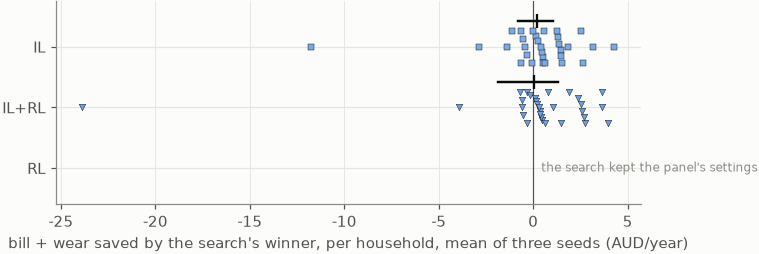

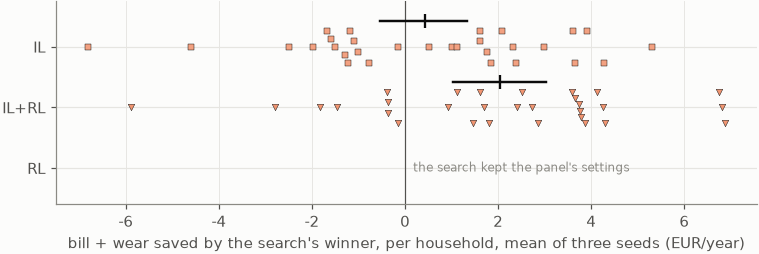

the search under the wide contract: validation on the tuning households (mean of the held-out weeks as they are
and at the scored year's price level, annualised, three seeds), and the test-year verdict where a winner differs
tariff learner  trials  pruned  households  validation, panel's settings  validation, winner  gain (val)  p (val)  kept the panel's  gain (test)  better on (test)  p_holm (test)
    AU      IL     144       0          16                       261.692             262.465       0.773    0.006             False        0.221              19.0          0.161
    AU   IL+RL      40      19           8                       282.438             283.749       1.311    0.023             False        0.042              21.0          0.098
    AU      RL      40      19           8                       274.698             274.698       0.000      NaN              True          NaN               NaN            NaN
    SI      IL     144       0          16                     

In [21]:
# The hyperparameter search under the wide contract (`rl_hpo`, its own root).
# Per study: what the search and the three-seed refine found on the tuning
# households' validation, and -- where refine picked something other than the
# panel's settings -- the three-seed verdict on the 30 study households' test
# year. One point per household: the seed-averaged change in bill + wear.
import os
import rl_hpo as hpo
HROOT = os.path.join(rx.HERE, "results_local", "rl_hpo_wide")
CONF = hpo.confirm_summary(root=HROOT)
HROWS = []
for name in hpo.list_studies(HROOT):
    s, w = hpo.read_settings(name, HROOT), hpo.winner(name, HROOT)
    tf = hpo.trials_frame(name, HROOT)
    c = CONF[CONF.study == name] if len(CONF) else CONF
    HROWS.append({
        "tariff": s["tariff"], "learner": METHOD_NAME[s["method"]],
        "trials": int(tf.state.isin(["COMPLETE", "PRUNED"]).sum()),
        "pruned": int((tf.state == "PRUNED").sum()),
        "households": len(s["households"]),
        "validation, panel's settings": w["incumbent_saving_val_a"],
        "validation, winner": w["mean_saving_val_a"],
        "gain (val)": w["delta_vs_incumbent"], "p (val)": w["p_vs_incumbent"],
        "kept the panel's": w["tag"] == w["incumbent_tag"],
        "gain (test)": float(c.gain.iloc[0]) if len(c) else np.nan,
        "better on (test)": int(c.n_better.iloc[0]) if len(c) else np.nan,
        "p_holm (test)": float(c.p_holm.iloc[0]) if len(c) else np.nan})
HTAB = pd.DataFrame(HROWS).sort_values(["tariff", "learner"])
for tariff in TARIFFS:
    fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.36))
    for i, m in enumerate(METHODS):
        col, mk = method_style(tariff, m)
        c = CONF[(CONF.tariff == tariff) & (CONF.method == m)]
        if c.empty:
            ax.text(0, i, "  the search kept the panel's settings", va="center",
                    fontsize=8, color=MUTED)
            continue
        d = np.asarray(c.d.iloc[0], dtype=float)
        ax.scatter(d, i + fs.beeswarm(d, height=0.26), marker=mk, s=18, color=col,
                   edgecolor=INK, lw=0.3, zorder=3)
        lo, hi = fs.boot_ci(d, stat=np.mean)
        ax.plot([lo, hi], [i - 0.42, i - 0.42], color=INK, lw=1.6, zorder=4)
        ax.scatter([d.mean()], [i - 0.42], marker="|", s=90, color=INK, zorder=5)
    ax.set_yticks(range(len(METHODS)))
    ax.set_yticklabels([METHOD_NAME[m] for m in METHODS])
    ax.set_ylim(len(METHODS) - 0.4, -0.75)
    ax.axvline(0, color=INK_2, lw=0.8)
    ax.xaxis.set_major_formatter(EUR)
    ax.grid(axis="x", color=pf.GRID, lw=0.6)
    ax.set_axisbelow(True)
    finish(ax, title=f"{tariff}: the searched settings against the panel's, wide "
                     f"contract, test year",
           xlabel=f"bill + wear saved by the search's winner, per household, mean "
                  f"of three seeds ({hs.money(tariff, 'year')})", ylabel="")
    pf.show(fig, f"rlf_hpo_{tariff}")
print("the search under the wide contract: validation on the tuning households "
      "(mean of the held-out weeks as they are\nand at the scored year's price "
      "level, annualised, three seeds), and the test-year verdict where a "
      "winner differs")
print(HTAB.round(3).to_string(index=False))
by_seed = []
for name in CONF.study if len(CONF) else []:
    df = hpo.confirm_frame(name, HROOT)
    w = df.pivot_table(index=["ident", "seed"], columns="label", values="test_net")
    g = (w["current"] - w["winner"]).unstack("seed")
    by_seed.append({"study": name, **{f"seed {s}": g[s].mean() for s in g.columns}})
print("\ntest-year gain by seed:")
print(pd.DataFrame(by_seed).round(2).to_string(index=False))
print("\nin force on the wide contract (`rb.VARIANT_TUNED`):",
      sorted(rb.VARIANT_TUNED.get(rb.WIDE_VARIANT, {})))